# Marketplace orders and delivery outcomes
**ENG2040 Assignment 1 — all five assessed steps**

This notebook turns the supplied `raw.sql` into audited order records, evidence about delivery
reliability, and numerical inputs available at approval. Run all cells in order, or run
`python run_notebook.py` after installing `requirements-notebook.txt`. Paths and analysis policies
are configured below. The input is never edited. Results are computed from the input, not embedded
as constants. The modified Olist extract is educational data (CC BY-NC-SA 4.0).

The five sections follow the brief's weights: loading 20%, cleaning 20%, analysis 30%, features 20%,
and reproducibility 10%. The notebook supplies data and evidence for the separate **6–8 page report
and oral examination**; it is not a substitute for that report. Analysis is descriptive, not causal.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import sqlite3
import tempfile
import threading
import time

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "assignment-matplotlib"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pycountry
from scipy.stats import norm
from IPython.display import Markdown, display

RAW_SQL = Path(os.getenv("RAW_SQL", "raw.sql")).expanduser().resolve()
OUT = Path(os.getenv("OUTPUT_DIR", str(RAW_SQL.parent / "assignment_outputs"))).expanduser().resolve()
MIN_GROUP = int(os.getenv("MIN_GROUP", "30"))  # Screening threshold, not a significance rule.
HOLDOUT_FRACTION = float(os.getenv("HOLDOUT_FRACTION", "0.2"))
CONFIDENCE = 0.95
EXTREME_QUANTILE = 0.99  # Exploratory sensitivity flag only; no automatic unit correction.
DATE_FORMATS = ("%Y-%m-%d %H:%M:%S", "%Y-%m-%dT%H:%M:%S", "%d/%m/%Y %H:%M:%S", "%Y-%m-%d")
assert RAW_SQL.is_file(), f"SQL input not found: {RAW_SQL}"
assert MIN_GROUP > 0 and 0 < HOLDOUT_FRACTION < 1
assert not RAW_SQL.is_relative_to(OUT), "Use a separate generated-output directory."
marker = OUT / ".generated-by-marketplace-notebook"
if OUT.exists() and any(OUT.iterdir()) and not marker.exists():
    raise ValueError(f"Refusing to write into an existing unmarked directory: {OUT}")
OUT.mkdir(parents=True, exist_ok=True)
marker.touch()
pd.set_option("display.max_columns", 18)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

### Shared output helpers

In [2]:
def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

INPUT_HASH = file_hash(RAW_SQL)
artifacts, resources, sql_log = [], [], []

def save(frame, relative, meaning):
    """Export a table and record its grain and estimated/actual CSV storage."""
    path = OUT / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    sample = frame.head(500).to_csv(index=False, lineterminator="\n", float_format="%.12g")
    estimate = len(sample.encode()) * len(frame) / max(len(frame.head(500)), 1)
    frame.to_csv(path, index=False, lineterminator="\n", float_format="%.12g")
    artifacts.append({"file": relative, "rows": len(frame), "meaning": meaning,
                      "estimated_bytes": round(estimate), "actual_bytes": path.stat().st_size})
    return frame

### Resource measurement helpers

In [3]:
def begin_step(name, estimated_incremental_bytes):
    """Sample RSS for the kernel and children; this is not an exact allocator peak."""
    process = psutil.Process()
    stop = threading.Event()
    state = {"step": name, "start": time.perf_counter(), "baseline_rss_bytes": process.memory_info().rss,
             "sampled_peak_rss_bytes": 0, "estimated_incremental_bytes": int(estimated_incremental_bytes),
             "artifact_start": len(artifacts), "disk_start": sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file()),
             "estimated_temporary_disk_bytes": 0, "observed_temporary_database_bytes": 0}
    def sample():
        while not stop.is_set():
            rss = process.memory_info().rss
            for child in process.children(recursive=True):
                try:
                    rss += child.memory_info().rss
                except psutil.Error:
                    pass
            state["sampled_peak_rss_bytes"] = max(state["sampled_peak_rss_bytes"], rss)
            stop.wait(0.05)
    worker = threading.Thread(target=sample, daemon=True)
    worker.start()
    return state, stop, worker

def end_step(meter, intermediate_bytes):
    state, stop, worker = meter
    stop.set()
    worker.join()
    state["runtime_seconds"] = time.perf_counter() - state.pop("start")
    state["measured_incremental_rss_bytes"] = max(0, state["sampled_peak_rss_bytes"] - state["baseline_rss_bytes"])
    state["intermediate_dataframe_bytes"] = int(intermediate_bytes)
    exports = artifacts[state.pop("artifact_start"):]
    state["estimated_csv_bytes"] = sum(a["estimated_bytes"] for a in exports)
    state["actual_csv_bytes"] = sum(a["actual_bytes"] for a in exports)
    state["output_disk_growth_bytes"] = sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file()) - state.pop("disk_start")
    resources.append(state)

def memory_of(frames):
    return sum(d.memory_usage(index=True, deep=True).sum() for d in frames)

## 1. Loading the Data (20%)

`orders` has one row per order; `customers` has one customer record per customer ID (the unique
customer ID can recur across orders). `products`, `sellers`, and `category_translation` are lookup
tables. Items use `(order_id, order_item_id)`; payments use `(order_id, payment_sequential)`;
reviews use `(review_id, order_id)`. Multiple payments and reviews must not multiply item totals.

Import the SQL into a separate generated SQLite database, check its schema/keys, and load each
table once. For this extract, pandas makes profiling and reusable rules transparent. We aggregate
each child table **before** joining to orders with cardinality checks. This avoids a wide
items × payments × reviews join. SQLite keeps a faithful disk copy; the memory estimate uses a
small per-table sample. A substantially larger input should use SQL pre-aggregation/chunked
processing rather than holding all tables in memory. We benchmark these two approaches below.
Child records referencing absent orders remain in the source/cleaned child exports and orphan log;
they cannot be assigned to invented orders. Known-order totals are reconciled separately. Raw money
aggregates include finite numeric observations (including negatives); malformed/non-finite values
are profiled and audited during cleaning, while the SQLite copy preserves every original value.

In [4]:
SCHEMA = {
    "orders": "order_id customer_id order_status order_purchase_timestamp order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date",
    "customers": "customer_id customer_unique_id customer_zip_code_prefix customer_city customer_state",
    "order_items": "order_id order_item_id product_id seller_id shipping_limit_date price freight_value",
    "order_payments": "order_id payment_sequential payment_type payment_installments payment_value",
    "order_reviews": "review_id order_id review_score review_comment_title review_comment_message review_creation_date review_answer_timestamp",
    "products": "product_id product_category_name product_name_lenght product_description_lenght product_photos_qty product_weight_g product_length_cm product_height_cm product_width_cm",
    "sellers": "seller_id seller_zip_code_prefix seller_city seller_state",
    "category_translation": "product_category_name product_category_name_english",
}
KEYS = {
    "orders": ["order_id"], "customers": ["customer_id"], "products": ["product_id"],
    "sellers": ["seller_id"], "category_translation": ["product_category_name"],
    "order_items": ["order_id", "order_item_id"], "order_payments": ["order_id", "payment_sequential"],
    "order_reviews": ["review_id", "order_id"],
}
RELATIONS = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("order_payments", "order_id", "orders", "order_id"),
    ("order_reviews", "order_id", "orders", "order_id"),
    ("products", "product_category_name", "category_translation", "product_category_name"),
]

### 1.1 Import a faithful SQLite copy

In [5]:
meter = begin_step("1_loading", RAW_SQL.stat().st_size * 4)
meter[0]["estimated_temporary_disk_bytes"] = RAW_SQL.stat().st_size
loading = OUT / "01_loading"
loading.mkdir(exist_ok=True)
DB = loading / "raw.sqlite"
# Build a new database each run; never read or overwrite a user's working database.
with tempfile.TemporaryDirectory(prefix="import-", dir=loading) as temporary:
    fresh_db = Path(temporary) / "raw.sqlite"
    with sqlite3.connect(fresh_db) as connection:
        connection.executescript(RAW_SQL.read_text(encoding="utf-8"))
        assert connection.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
    meter[0]["observed_temporary_database_bytes"] = fresh_db.stat().st_size
    os.replace(fresh_db, DB)

def query(connection, statement):
    sql_log.append(statement)
    return pd.read_sql_query(statement, connection)

### 1.2 Validate schema and primary keys

In [6]:
raw, inventory = {}, []
with sqlite3.connect(f"{DB.as_uri()}?mode=ro", uri=True) as connection:
    tables = query(connection, "SELECT name, sql FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name")
    missing_tables = set(SCHEMA) - set(tables["name"])
    if missing_tables:
        raise ValueError(f"Missing required tables: {sorted(missing_tables)}")
    for table, columns in SCHEMA.items():
        info = query(connection, f'PRAGMA table_info("{table}")')
        missing = set(columns.split()) - set(info["name"])
        if missing:
            raise ValueError(f"{table}: missing columns {sorted(missing)}")
        rows = query(connection, f'SELECT COUNT(*) AS n FROM "{table}"').iloc[0, 0]
        sample = query(connection, f'SELECT * FROM "{table}" LIMIT 500')
        estimate = memory_of([sample]) / max(len(sample), 1) * rows
        data = query(connection, f'SELECT * FROM "{table}"').sort_values(KEYS[table]).reset_index(drop=True)
        if data[KEYS[table]].isna().any().any() or data.duplicated(KEYS[table]).any():
            raise ValueError(f"{table}: missing or duplicate primary keys")
        for key in KEYS[table]:
            if data[key].astype("string").str.strip().eq("").any():
                raise ValueError(f"{table}: blank key {key}")
        raw[table] = data
        inventory.append({"table": table, "rows": int(rows), "columns": len(data.columns),
                          "estimated_dataframe_bytes": int(estimate), "actual_dataframe_bytes": memory_of([data])})
    save(tables, "01_loading/schema.csv", "One row per SQL table, including its original CREATE statement")

### 1.3 Check relationships without dropping orders

In [7]:
save(pd.DataFrame(inventory), "01_loading/table_inventory.csv", "One row per required input table")
relationship_rows, orphan_rows = [], []
for child, foreign, parent, primary in RELATIONS:
    values = raw[child][foreign]
    missing = values.isna()
    orphan = values.notna() & ~values.isin(raw[parent][primary])
    relationship_rows.append({"child": child, "foreign_key": foreign, "parent": parent,
                              "rows": len(values), "missing": int(missing.sum()), "orphans": int(orphan.sum())})
    detail = raw[child].loc[orphan, KEYS[child] + ([foreign] if foreign not in KEYS[child] else [])].copy()
    detail["relationship"] = f"{child}.{foreign} -> {parent}.{primary}"
    orphan_rows.append(detail)
save(pd.DataFrame(relationship_rows), "01_loading/relationships.csv", "One row per documented relationship; missing and orphan counts")
save(pd.concat(orphan_rows, ignore_index=True), "01_loading/orphan_records.csv", "One row per broken reference, with its source key")

,order_id,customer_id,relationship,order_item_id,product_id,seller_id,payment_sequential,review_id,product_category_name
0,007ec946d4f798caf2b43c9d44c56421,8b8475780c8476ea1605184dbce7833d,orders.customer_id -> customers.customer_id,NaN,NaN,NaN,NaN,NaN,NaN
1,009838529bb913846ab6670d22865381,bfc6b41e350284854dc5fb31b003a212,orders.customer_id -> customers.customer_id,NaN,NaN,NaN,NaN,NaN,NaN
2,013bc5ce14f856d31efc8bebdc3a278f,133a06859091240dc090f61848a0bdca,orders.customer_id -> customers.customer_id,NaN,NaN,NaN,NaN,NaN,NaN
3,01ccc64a2b38fdb87c25cb1944934670,f23d5a299d6196b918126dbf926babfe,orders.customer_id -> customers.customer_id,NaN,NaN,NaN,NaN,NaN,NaN
4,01f48b2a27229e667db384b5b9d5dfa4,409e2d7eac2a38905d9c8cebb757bc9b,orders.customer_id -> customers.customer_id,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
3322,NaN,NaN,products.product_category_name -> category_tra...,NaN,fe1d68f123061329a6d3505c2b905566,NaN,NaN,NaN,unmapped_category
3323,NaN,NaN,products.product_category_name -> category_tra...,NaN,fe59a1e006df3ac42bf0ceb876d70969,NaN,NaN,NaN,INFORMATICA_ACESSORIOS
3324,NaN,NaN,products.product_category_name -> category_tra...,NaN,fe9dfbe7f974621789683b7b78be2a16,NaN,NaN,NaN,unmapped_category
3325,NaN,NaN,products.product_category_name -> category_tra...,NaN,ffa4027b0effa4df0d5f5a9ce2788b6d,NaN,NaN,NaN,unmapped_category


### 1.4 Aggregate child records before joining and reconcile totals

In [8]:
def sum_complete(series):
    return series.sum(min_count=len(series)) if len(series) else np.nan

def assemble(orders, customers, item_summary, payment_summary, review_summary):
    result = orders.merge(customers, on="customer_id", how="left", validate="many_to_one")
    for summary in [item_summary, payment_summary, review_summary]:
        result = result.merge(summary, on="order_id", how="left", validate="one_to_one")
    assert len(result) == len(orders) and result["order_id"].is_unique
    return result.sort_values("order_id").reset_index(drop=True)

def finite_numeric(series):
    values = pd.to_numeric(series, errors="coerce")
    return values.where(np.isfinite(values))

raw_item_numbers = raw["order_items"].assign(price=finite_numeric(raw["order_items"]["price"]), freight_value=finite_numeric(raw["order_items"]["freight_value"]))
raw_payment_numbers = raw["order_payments"].assign(payment_value=finite_numeric(raw["order_payments"]["payment_value"]))
raw_items = raw_item_numbers.groupby("order_id", sort=True).agg(
    item_count=("order_item_id", "size"), raw_price_observed_brl=("price", lambda s: s.sum(min_count=1)),
    raw_price_complete_brl=("price", sum_complete), raw_freight_observed_brl=("freight_value", lambda s: s.sum(min_count=1)))
raw_payments = raw_payment_numbers.groupby("order_id", sort=True).agg(
    payment_count=("payment_sequential", "size"), raw_payment_observed_centavos=("payment_value", lambda s: s.sum(min_count=1)))
raw_reviews = raw["order_reviews"].groupby("order_id", sort=True).agg(review_count=("review_id", "size"))
loaded = assemble(raw["orders"], raw["customers"], raw_items, raw_payments, raw_reviews)
save(loaded, "01_loading/orders_loaded.csv", "One row per original order; raw child aggregates, no cleaning")

reconciliation = []
def reconcile(name, expected, actual):
    ok = bool(np.isclose(expected, actual, equal_nan=True))
    reconciliation.append({"check": name, "expected": expected, "actual": actual, "passed": ok})
    assert ok, f"Reconciliation failed: {name} ({expected} vs {actual})"

reconcile("All orders preserved", len(raw["orders"]), len(loaded))
reconcile("Item rows represented", len(raw["order_items"]), raw_items["item_count"].sum())
reconcile("Payment rows represented", len(raw["order_payments"]), raw_payments["payment_count"].sum())
reconcile("Review rows represented", len(raw["order_reviews"]), raw_reviews["review_count"].sum())
reconcile("Raw observed item price total", raw_item_numbers["price"].sum(), raw_items["raw_price_observed_brl"].sum())
reconcile("Raw observed freight total", raw_item_numbers["freight_value"].sum(), raw_items["raw_freight_observed_brl"].sum())
reconcile("Raw observed payment total (centavos)", raw_payment_numbers["payment_value"].sum(), raw_payments["raw_payment_observed_centavos"].sum())
for table, column in [("order_items", "item_count"), ("order_payments", "payment_count"), ("order_reviews", "review_count")]:
    linked = raw[table].order_id.isin(raw["orders"].order_id)
    reconcile(f"Known-order {table} rows represented after join", linked.sum(), loaded[column].sum())
for frame, source, target in [(raw_item_numbers, "price", "raw_price_observed_brl"), (raw_item_numbers, "freight_value", "raw_freight_observed_brl"), (raw_payment_numbers, "payment_value", "raw_payment_observed_centavos")]:
    linked = frame.order_id.isin(raw["orders"].order_id)
    reconcile(f"Known-order {source} total after join", frame.loc[linked, source].sum(), loaded[target].sum())
display(pd.DataFrame(inventory), pd.DataFrame(relationship_rows))

,table,rows,columns,estimated_dataframe_bytes,actual_dataframe_bytes
0,orders,20000,8,11136679,11127970
1,customers,20000,5,6450320,6453214
2,order_items,22662,7,7567838,7554194
3,order_payments,20875,5,3433311,3432063
4,order_reviews,19966,7,8012914,7965932
5,products,11334,9,2250841,2258445
6,sellers,2071,4,505162,504862
7,category_translation,73,2,9635,9635


,child,foreign_key,parent,rows,missing,orphans
0,orders,customer_id,customers,20000,0,769
1,order_items,order_id,orders,22662,0,0
2,order_items,product_id,products,22662,0,910
3,order_items,seller_id,sellers,22662,0,893
4,order_payments,order_id,orders,20875,0,0
5,order_reviews,order_id,orders,19966,0,0
6,products,product_category_name,category_translation,11334,509,755


In [9]:
# Compare a representative aggregation without claiming either tool is always faster.
benchmark = []
with sqlite3.connect(f"{DB.as_uri()}?mode=ro", uri=True) as connection:
    for engine in ["SQLite", "pandas"]:
        start = time.perf_counter()
        if engine == "SQLite":
            bound = np.finfo(float).max
            statement = f"SELECT order_id, COUNT(*) AS item_count, SUM(CASE WHEN typeof(price) IN ('integer','real') AND price BETWEEN {-bound} AND {bound} THEN price END) AS price FROM order_items GROUP BY order_id ORDER BY order_id"
            result = query(connection, statement)
        else:
            result = raw_item_numbers.groupby("order_id", sort=True).agg(item_count=("price", "size"), price=("price", lambda s: s.sum(min_count=1))).reset_index()
        benchmark.append({"engine": engine, "seconds": time.perf_counter() - start,
                          "output_rows": len(result), "output_dataframe_bytes": memory_of([result])})
        if engine == "SQLite":
            sql_result = result
        else:
            pd.testing.assert_frame_equal(sql_result, result, check_dtype=False, rtol=1e-10)
save(pd.DataFrame(benchmark), "01_loading/aggregation_benchmark.csv", "One row per engine for the same raw item aggregation")
end_step(meter, memory_of(list(raw.values()) + [loaded, raw_item_numbers, raw_payment_numbers]))
display(pd.DataFrame(benchmark))
display(Markdown("Timing is one warm-machine run; pandas input is already in memory, while SQLite includes reading and materialising its result. This is a scoped comparison, not an end-to-end performance ranking."))

,engine,seconds,output_rows,output_dataframe_bytes
0,SQLite,0.020337,19858,1926358
1,pandas,0.395265,19858,1926358


Timing is one warm-machine run; pandas input is already in memory, while SQLite includes reading and materialising its result. This is a scoped comparison, not an end-to-end performance ranking.

## 2. Data Quality and Cleaning (20%)

Rules follow business meaning rather than specific IDs or the current row counts:

* Normalise text with whitespace trimming and consistent case; retain unknown status/category
  values. State codes are checked against the **ISO Brazilian subdivision reference** supplied by
  `pycountry`, not against whichever states happen to appear in the extract. Unknown locations stay missing.
* Parse only the declared local-clock formats; impossible/unsupported dates become missing and
  are audited. No timezone conversion or guessed date repair is applied.
* Negative/non-finite money, invalid counts, review scores outside 1–5, and non-positive physical
  dimensions become missing. Zero money and zero payment installments remain valid. Payment
  values are divided by 100 because the brief specifies centavos; item amounts remain BRL.
* Incomplete baskets have **partial observed totals and separate complete totals**. We do not
  present a partial sum as a complete basket. Missing catalogue attributes do not exclude an order.
* Labels require status `delivered`, valid approval/estimate/delivery dates, and consistent recorded
  event chronology. Purchase and carrier dates can be missing, but supplied malformed values or
  observed contradictions invalidate the outcome. Missing carrier/purchase records are tested in a
  stricter sensitivity cohort. An estimate on the approval day is valid even when stored at midnight.
* Lateness compares **calendar dates**: delivery any time on the estimated date is on time.
  Cancelled, unknown, incomplete, or contradictory outcomes remain unlabelled, not zero.
* Large positive amounts/dimensions are not rescaled without evidence of their units. Exploratory
  quantile flags support sensitivity analysis; they do not define production cleaning or features.

All orders survive the joins. An explicit eligibility flag separates approval-time prediction records
from records lacking required approval/estimate information; label exclusions have separate reasons.

In [10]:
meter = begin_step("2_cleaning", memory_of(list(raw.values())) * 3)
clean = {name: frame.copy() for name, frame in raw.items()}
changes, flags = [], {name: pd.DataFrame(index=d.index) for name, d in raw.items()}
BR_STATES = {s.code.split("-", 1)[1] for s in pycountry.subdivisions.get(country_code="BR")}

def normalise(series, upper=False):
    result = series.astype("string").str.strip().replace("", pd.NA)
    return result.str.upper() if upper else result.str.lower()

def parse_dates(series):
    text = series.astype("string").str.strip().replace("", pd.NA)
    result = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    for fmt in DATE_FORMATS:
        candidate = pd.to_datetime(text, format=fmt, errors="coerce", exact=True)
        result = result.fillna(candidate)
    return result

def valid_numbers(series, minimum=0, integer=False, positive=False, maximum=None):
    result = pd.to_numeric(series, errors="coerce").astype(float)
    valid = np.isfinite(result) & (result.gt(minimum) if positive else result.ge(minimum))
    if integer:
        valid &= result.eq(np.floor(result))
    if maximum is not None:
        valid &= result.le(maximum)
    return result.where(valid)

def record(table, column, new, rule):
    old = clean[table][column]
    before, after = old.astype("string"), new.astype("string")
    changed = before.fillna("<NULL>").ne(after.fillna("<NULL>"))
    # Date format changes are recorded as well as rejected values.
    part = clean[table].loc[changed, KEYS[table]].copy()
    part["table"], part["column"], part["rule"] = table, column, rule
    part["original"], part["cleaned"] = before[changed], after[changed]
    changes.append(part)
    flags[table][column + "_missing"] = new.isna()
    flags[table][column + "_invalid"] = old.notna() & new.isna()
    clean[table][column] = new

### 2.1 Normalise text and parse dates

In [11]:
for table, data in clean.items():
    for column in data.columns:
        if (column in KEYS[table] and column != "product_category_name") or (column.endswith("_id") and column != "customer_unique_id"):
            continue
        if column == "customer_unique_id":
            record(table, column, data[column].astype("string").str.strip().replace("", pd.NA), "Trim optional unique-customer ID; blank -> missing")
        elif "timestamp" in column or "date" in column or column == "order_approved_at":
            record(table, column, parse_dates(data[column]), "Parse declared local date formats; invalid -> missing")
        elif column.endswith("_state"):
            state = normalise(data[column], upper=True)
            record(table, column, state.where(state.isin(BR_STATES)), "Trim/uppercase; validate ISO BR state code")
        elif column.endswith("_city") or column in ["order_status", "payment_type", "product_category_name", "product_category_name_english"]:
            record(table, column, normalise(data[column]), "Trim and lowercase text; blanks -> missing")
        elif column.endswith("zip_code_prefix"):
            postal = data[column].astype("string").str.strip()
            postal = postal.where(postal.str.fullmatch(r"\d{1,5}", na=False)).str.zfill(5)
            record(table, column, postal, "Preserve postal prefix as five-digit text; invalid -> missing")

### 2.2 Validate numerical domains and record sequence anomalies

In [12]:
PRODUCT_NUMERIC = "product_name_lenght product_description_lenght product_photos_qty product_weight_g product_length_cm product_height_cm product_width_cm".split()
NUMERIC_RULES = {
    "order_items": {"price": {}, "freight_value": {}},
    "order_payments": {"payment_value": {"integer": True}, "payment_installments": {"integer": True}},
    "order_reviews": {"review_score": {"minimum": 1, "maximum": 5, "integer": True}},
    "products": {c: {"positive": c in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"],
                      "integer": c in ["product_name_lenght", "product_description_lenght", "product_photos_qty"]}
                 for c in PRODUCT_NUMERIC},
}
for table, rules in NUMERIC_RULES.items():
    for column, options in rules.items():
        record(table, column, valid_numbers(clean[table][column], **options), "Domain/range validation; invalid -> missing")

# Normalisation must not make lookup keys ambiguous.
for table in clean:
    if clean[table][KEYS[table]].isna().any().any() or clean[table].duplicated(KEYS[table]).any():
        raise ValueError(f"{table}: missing/colliding keys after normalisation; inspect rather than silently deduplicate")

sequence_issues = []
for table, sequence in [("order_items", "order_item_id"), ("order_payments", "payment_sequential")]:
    data = clean[table]
    values = pd.to_numeric(data[sequence], errors="coerce")
    invalid = ~np.isfinite(values) | values.lt(1) | values.ne(np.floor(values))
    flags[table][sequence + "_invalid"] = invalid
    summary = data.assign(_sequence=values, _invalid=invalid).groupby("order_id").agg(
        rows=(sequence, "size"), smallest=("_sequence", "min"), largest=("_sequence", "max"), distinct=("_sequence", "nunique"), invalid=("_invalid", "sum"))
    gap = summary.invalid.gt(0) | summary.smallest.ne(1) | summary.largest.ne(summary.rows) | summary.distinct.ne(summary.rows)
    part = summary.loc[gap, ["rows"]].reset_index()
    part["table"] = table
    part["issue"] = "Sequence is not contiguous positive integers from 1; retained without renumbering"
    sequence_issues.append(part)
save(pd.concat(sequence_issues, ignore_index=True),
     "02_cleaning/sequence_issues.csv", "One order/table with a sequence anomaly; no row is silently removed or renumbered")

,order_id,rows,table,issue
0,00ac05fe0fc047c54418098eb64e3aaa,1,order_payments,Sequence is not contiguous positive integers f...
1,056c68d093c100017aab1f00f260705c,1,order_payments,Sequence is not contiguous positive integers f...
2,166b01d0fce75a595b92ad9e84e0843b,1,order_payments,Sequence is not contiguous positive integers f...
3,1a57108394169c0b47d8f876acc9ba2d,1,order_payments,Sequence is not contiguous positive integers f...
4,229d2824e311bf2592b6b7ce32af04a8,1,order_payments,Sequence is not contiguous positive integers f...
5,3ed99ad145f818a65b1bcfce6a4182fb,1,order_payments,Sequence is not contiguous positive integers f...
6,45c6469f0136458ebcb1ae34e7a4c3b9,1,order_payments,Sequence is not contiguous positive integers f...
7,4b2dcf714729a31ae2d3b69b1dd35629,1,order_payments,Sequence is not contiguous positive integers f...
8,66b28b67d37eb8809a5cf1cc3ceb8310,1,order_payments,Sequence is not contiguous positive integers f...
9,7897a2eebb3941ae97159cb88f65cb1c,1,order_payments,Sequence is not contiguous positive integers f...


### 2.3 Export profiles, changes and per-record flags

In [13]:
profile = []
for table, data in raw.items():
    for column in data:
        text = data[column].astype("string")
        profile.append({"table": table, "column": column, "rows": len(data), "raw_missing": int(data[column].isna().sum()),
                        "blank_text": int(text.str.strip().eq("").sum()), "raw_distinct": data[column].nunique(dropna=True),
                        "clean_missing": int(clean[table][column].isna().sum()),
                        "invalid_to_missing": int(flags[table].get(column + "_invalid", pd.Series(False, index=data.index)).sum())})
save(pd.DataFrame(profile), "02_cleaning/column_profile.csv", "One row per source column, before/after missingness and invalid counts")
save(pd.concat(changes, ignore_index=True), "02_cleaning/cell_changes.csv", "One row per changed value, with source keys and rule")
for table in clean:
    save(clean[table], f"02_cleaning/tables/{table}.csv", f"One cleaned {table} record; original row grain preserved")
    save(pd.concat([clean[table][KEYS[table]], flags[table]], axis=1), f"02_cleaning/flags/{table}.csv", f"One {table} record with missing/invalid field flags")
display(pd.DataFrame(profile).query("invalid_to_missing > 0"))

,table,column,rows,raw_missing,blank_text,raw_distinct,clean_missing,invalid_to_missing
3,orders,order_purchase_timestamp,20000,168,0,19652,333,165
4,orders,order_approved_at,20000,199,0,19224,351,152
5,orders,order_delivered_carrier_date,20000,483,0,18330,632,149
6,orders,order_delivered_customer_date,20000,714,0,19092,875,161
7,orders,order_estimated_delivery_date,20000,160,0,423,330,170
10,customers,customer_zip_code_prefix,20000,306,0,8520,1226,920
12,customers,customer_state,20000,305,0,53,1185,880
17,order_items,shipping_limit_date,22662,857,0,18300,1759,902
18,order_items,price,22662,439,0,3302,847,408
19,order_items,freight_value,22662,427,0,4445,885,458


In [14]:
def dominant_category(items):
    counts = items.dropna(subset=["product_category_name"]).groupby(["order_id", "product_category_name"]).size().rename("n").reset_index()
    # Highest item count wins; alphabetical ties are deterministic, never value-based findings.
    counts = counts.sort_values(["order_id", "n", "product_category_name"], ascending=[True, False, True])
    return counts.drop_duplicates("order_id").set_index("order_id")["product_category_name"].rename("dominant_category")

### 2.4 Assemble cleaned order-level aggregates

In [15]:
items = clean["order_items"].merge(clean["products"], on="product_id", how="left", validate="many_to_one", indicator="product_link")
items = items.merge(clean["sellers"], on="seller_id", how="left", validate="many_to_one", indicator="seller_link")
items = items.merge(clean["orders"][["order_id", "customer_id"]], on="order_id", how="left", validate="many_to_one")
items = items.merge(clean["customers"][["customer_id", "customer_state"]], on="customer_id", how="left", validate="many_to_one")
items["location_known"] = items["seller_state"].notna() & items["customer_state"].notna()
items["cross_state"] = items["seller_state"].ne(items["customer_state"]).where(items["location_known"]).astype(float)
items["catalogue_missing"] = items["product_weight_g"].isna() | items["product_category_name"].isna()
items["product_orphan"] = items["product_link"].eq("left_only")
items["seller_orphan"] = items["seller_link"].eq("left_only")
items["volume_cm3"] = items["product_length_cm"] * items["product_height_cm"] * items["product_width_cm"]
items["volume_cm3"] = items["volume_cm3"].where(np.isfinite(items["volume_cm3"]))

item_summary = items.groupby("order_id", sort=True).agg(
    item_count=("order_item_id", "size"), seller_count=("seller_id", "nunique"), product_count=("product_id", "nunique"),
    category_count=("product_category_name", "nunique"), basket_value_brl=("price", sum_complete),
    observed_value_brl=("price", lambda s: s.sum(min_count=1)), freight_brl=("freight_value", sum_complete),
    observed_freight_brl=("freight_value", lambda s: s.sum(min_count=1)),
    price_missing_count=("price", lambda s: s.isna().sum()), freight_missing_count=("freight_value", lambda s: s.isna().sum()),
    weight_g=("product_weight_g", sum_complete), volume_cm3=("volume_cm3", sum_complete),
    mean_photos=("product_photos_qty", "mean"), catalogue_missing_fraction=("catalogue_missing", "mean"),
    product_orphan_count=("product_orphan", "sum"), seller_orphan_count=("seller_orphan", "sum"),
    seller_geography_known_fraction=("location_known", "mean"), cross_state_fraction=("cross_state", "mean"))
item_summary = item_summary.join(dominant_category(items))
payments = clean["order_payments"].copy()
payments["payment_brl"] = payments["payment_value"] / 100
payment_summary = payments.groupby("order_id", sort=True).agg(
    payment_count=("payment_sequential", "size"), payment_brl=("payment_brl", sum_complete),
    observed_payment_brl=("payment_brl", lambda s: s.sum(min_count=1)),
    invalid_payment_fields=("payment_installments", lambda s: s.isna().sum()))
review_summary = clean["order_reviews"].groupby("order_id", sort=True).agg(
    review_count=("review_id", "size"), mean_review_score=("review_score", "mean"))
orders = assemble(clean["orders"], clean["customers"], item_summary, payment_summary, review_summary)
orders = orders.merge(pd.concat([clean["orders"][["order_id"]], flags["orders"]], axis=1), on="order_id", validate="one_to_one")
orders["no_item_records"] = orders["item_count"].isna()
orders["customer_orphan"] = ~orders["customer_id"].isin(clean["customers"]["customer_id"])
count_columns = ["item_count", "seller_count", "product_count", "category_count", "product_orphan_count", "seller_orphan_count", "payment_count", "review_count"]
orders[count_columns] = orders[count_columns].fillna(0)
orders["basket_total_brl"] = orders["basket_value_brl"] + orders["freight_brl"]
orders["freight_share"] = orders["freight_brl"].div(orders["basket_total_brl"].where(orders["basket_total_brl"].gt(0)))
orders["payment_difference_brl"] = orders["payment_brl"] - orders["basket_total_brl"]
orders["payment_mismatch"] = orders["payment_difference_brl"].abs().gt(0.01)  # One cent is a monetary rounding tolerance.
orders["payment_comparable"] = orders["payment_difference_brl"].notna()
payment_summary_audit = pd.DataFrame([{"metric": "Comparable complete item/payment totals", "orders": int(orders.payment_comparable.sum())},
                                      {"metric": "Difference exceeds one cent", "orders": int((orders.payment_comparable & orders.payment_mismatch).sum())},
                                      {"metric": "Uncomparable incomplete totals", "orders": int((~orders.payment_comparable).sum())}])
save(payment_summary_audit, "02_cleaning/payment_reconciliation_coverage.csv", "One reconciliation outcome; payments are diagnostics, never predictors")
orders["geography"] = np.select(
    [orders["seller_geography_known_fraction"].ne(1).fillna(True), orders["cross_state_fraction"].eq(0), orders["cross_state_fraction"].eq(1)],
    ["unknown", "same_state", "cross_state"], default="mixed_states")

### 2.5 Define reliable calendar-day labels

In [16]:
def label_orders(frame):
    """Return flags and nullable labels without using item/catalogue completeness."""
    result = frame.copy()
    purchase = result["order_purchase_timestamp"]
    approved = result["order_approved_at"]
    carrier = result["order_delivered_carrier_date"]
    delivered = result["order_delivered_customer_date"]
    estimated = result["order_estimated_delivery_date"]
    result["approval_before_purchase"] = approved.lt(purchase)
    result["carrier_before_approval"] = carrier.lt(approved)
    result["delivery_before_approval"] = delivered.lt(approved)
    result["delivery_before_carrier"] = delivered.lt(carrier)
    result["estimate_before_approval_day"] = estimated.dt.normalize().lt(approved.dt.normalize())
    date_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
    result["invalid_recorded_date"] = result.reindex(columns=[c + "_invalid" for c in date_columns], fill_value=False).fillna(False).any(axis=1)
    chronological = ["approval_before_purchase", "carrier_before_approval", "delivery_before_approval", "delivery_before_carrier", "estimate_before_approval_day"]
    result["chronology_problem"] = result[chronological].any(axis=1)
    result["approval_eligible"] = approved.notna() & estimated.notna() & ~result["approval_before_purchase"] & ~result["estimate_before_approval_day"]
    reasons = pd.DataFrame({
        "status_not_delivered": result["order_status"].ne("delivered").fillna(True),
        "missing_approval": approved.isna(), "missing_estimate": estimated.isna(), "missing_delivery": delivered.isna(),
        "invalid_recorded_date": result["invalid_recorded_date"], "chronology_problem": result["chronology_problem"],
    }, index=result.index)
    result["label_usable"] = ~reasons.any(axis=1)
    result["label_exclusion_reasons"] = reasons.apply(lambda row: ";".join(row.index[row]), axis=1)
    result["delay_days"] = (delivered.dt.normalize() - estimated.dt.normalize()).dt.days.where(result["label_usable"])
    result["delivered_after_estimate"] = result["delay_days"].gt(0).astype("Int64").where(result["label_usable"])
    result["promise_window_days"] = (estimated.dt.normalize() - approved.dt.normalize()).dt.days.where(result["approval_eligible"])
    result["approval_wait_hours"] = (approved - purchase).dt.total_seconds().div(3600).where(~result["approval_before_purchase"])
    return result, reasons

### 2.6 Apply labels, retain uncertainty and reconcile outputs

In [17]:
orders, label_reasons = label_orders(orders)
orders["extreme_positive_value"] = False
extreme_thresholds = []
for column in ["basket_value_brl", "freight_brl", "weight_g", "volume_cm3"]:
    threshold = orders[column].quantile(EXTREME_QUANTILE)
    orders["extreme_positive_value"] |= orders[column].gt(threshold)
    extreme_thresholds.append({"column": column, "quantile": EXTREME_QUANTILE, "threshold": threshold,
                               "flagged_orders": int(orders[column].gt(threshold).sum())})
save(pd.DataFrame(extreme_thresholds), "02_cleaning/exploratory_extreme_flags.csv", "Data-driven screening thresholds; not production transformations")
save(orders, "02_cleaning/orders_clean.csv", "One row per original order; clean aggregates, quality flags, nullable label")
save(pd.concat([orders[["order_id"]], label_reasons], axis=1), "02_cleaning/label_exclusions.csv", "One row per order; overlapping reasons for unavailable labels")
save(orders.groupby("label_exclusion_reasons", dropna=False).size().rename("orders").reset_index(),
     "02_cleaning/label_reason_combinations.csv", "One row per mutually exclusive combination of label reasons; empty means labelled")
save(orders.groupby(["approval_eligible", "label_usable"], dropna=False).size().rename("orders").reset_index(),
     "02_cleaning/cohort_flow.csv", "One row per approval/label eligibility combination, summing to all orders")
for name, source, summary in [
    ("clean observed price", items["price"], item_summary["observed_value_brl"]),
    ("clean observed freight", items["freight_value"], item_summary["observed_freight_brl"]),
    ("clean observed payment BRL", payments["payment_brl"], payment_summary["observed_payment_brl"]),
]:
    reconcile(name, source.sum(), summary.sum())
for frame, source, target in [(items, "price", "observed_value_brl"), (items, "freight_value", "observed_freight_brl"), (payments, "payment_brl", "observed_payment_brl")]:
    linked = frame.order_id.isin(orders.order_id)
    reconcile(f"Clean known-order {source} total after join", frame.loc[linked, source].sum(), orders[target].sum())
reconcile("Clean order IDs retained", len(raw["orders"]), len(orders))
assert set(orders["order_id"]) == set(raw["orders"]["order_id"])
assert orders.loc[~orders["label_usable"], "delivered_after_estimate"].isna().all()
save(pd.DataFrame(reconciliation), "02_cleaning/reconciliation.csv", "One assertion per count or money-total reconciliation")
end_step(meter, memory_of(list(clean.values()) + [items, orders]))
display(orders["label_exclusion_reasons"].value_counts().rename_axis("reason combination").to_frame("orders"))

,orders
reason combination,
,15648
status_not_delivered,1495
chronology_problem,1007
status_not_delivered;missing_delivery,479
invalid_recorded_date,302
missing_delivery,174
missing_approval,165
missing_estimate;invalid_recorded_date,159
missing_estimate,156


## 3. Exploratory Analysis (30%)

The main denominator is **orders with a usable completed-delivery label**, including orders with
optional catalogue/location gaps. Every rate table reports its denominator and a 95% Wilson
interval. These intervals approximate binomial uncertainty conditional on the observed cohort;
they do not correct selection bias, repeated customers/sellers, or multiple comparisons. Small
groups remain in exported data but are not promoted as priority findings.

Calendar-day differences measure early/on-time/late delivery; positive delay summaries use late
orders only. Quantile bands are discovered from the current data and used for exploration, never
as learned model thresholds. Missing predictor values have their own group rather than silently
disappearing. Further analyses are chosen for interpretable operational questions, not chart count.

In [18]:
meter = begin_step("3_analysis", memory_of([orders]) * 2)
labelled = orders.loc[orders["label_usable"]].copy()
if labelled.empty:
    raise ValueError("No reliable completed deliveries; inspect label_exclusions.csv before analysis.")
labelled["late"] = labelled["delivered_after_estimate"].astype(int)
notes = []
def note(text):
    notes.append(text)
    display(Markdown(text))

def wilson(successes, counts, confidence=CONFIDENCE):
    rate = successes / counts
    z = norm.ppf((1 + confidence) / 2)
    denominator = 1 + z*z / counts
    centre = (rate + z*z / (2*counts)) / denominator
    half = z*np.sqrt(rate*(1-rate)/counts + z*z/(4*counts**2)) / denominator
    return centre-half, centre+half

def rates(data, group):
    values = data[group].astype("string").fillna("Unknown / missing")
    grouped = data.assign(_group=values).groupby("_group", sort=True)
    result = grouped.agg(n=("late", "size"), late=("late", "sum"),
                         late_median_days=("delay_days", lambda s: s[s.gt(0)].median()),
                         late_p90_days=("delay_days", lambda s: s[s.gt(0)].quantile(0.9)))
    result["rate"] = result["late"] / result["n"]
    result["low"], result["high"] = wilson(result["late"], result["n"])
    result["screening_support"] = result["n"].ge(MIN_GROUP)
    result = result.rename_axis(group).reset_index()
    if isinstance(data[group].dtype, pd.CategoricalDtype):
        order = {str(value): i for i, value in enumerate(data[group].cat.categories)}
        result = result.iloc[np.argsort(result[group].map(order).fillna(len(order)).to_numpy())].reset_index(drop=True)
    return result

def bands(series, groups=5):
    if series.dropna().nunique() < 2:
        return pd.Series(np.where(series.notna(), "Single observed value", "Unknown / missing"), index=series.index)
    result = pd.qcut(series, q=min(groups, series.nunique()), duplicates="drop")
    result = result.cat.rename_categories(lambda interval: str(interval))
    return result.cat.add_categories(["Unknown / missing"]).fillna("Unknown / missing")

def figure(name, chart_data, meaning):
    save(chart_data, f"03_analysis/chart_data/{name}.csv", meaning)
    path = OUT / "03_analysis/figures" / f"{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

def rate_chart(table, group, title, name):
    plotted = table.loc[table["screening_support"]].copy()
    if plotted.empty:
        note(f"**{title}:** no group meets the configured minimum support. See the full exported table; no stable ranking is claimed.")
        return
    x = np.arange(len(plotted))
    plt.figure(figsize=(max(7, min(14, len(plotted)*0.5)), 4))
    plt.errorbar(x, plotted["rate"]*100, yerr=np.vstack([(plotted["rate"]-plotted["low"])*100, (plotted["high"]-plotted["rate"])*100]), fmt="o", capsize=3)
    plt.xticks(x, plotted[group], rotation=45, ha="right")
    plt.ylabel("Late deliveries (%)")
    plt.title(title + "\n95% Wilson intervals")
    figure(name, table, f"One {group} group; n is labelled orders; all groups exported")

### 3.1 How often deliveries are late and by how long

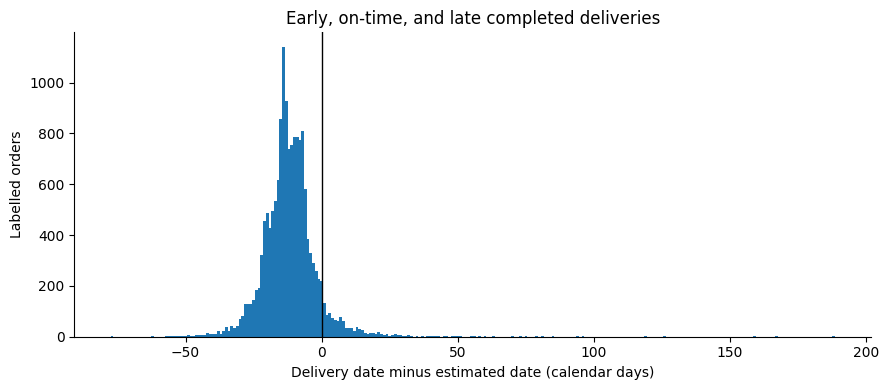

**Required question 1 — frequency and severity.** 1,064/15,648 usable deliveries were late (6.8%; conditional 95% interval 6.4%–7.2%). Usable labels cover 78.2% of all orders. Among late deliveries, the median was 7.0 days and the 90th percentile was 22.0 days. The signed distribution distinguishes early deliveries from punctual deliveries; extreme observations remain visible. Recorded-delivered orders with unusable labels could move the late fraction anywhere between 5.9% and 18.7%; this is a worst-case missing-outcome bound, not an estimate. Operations should track both the late share and the long-delay tail; excluded outcomes and extract composition limit generalisation.

,metric,value
0,All input orders,20000.000000
1,Approval eligible,19317.000000
2,Recorded delivered status,17930.000000
3,Usable delivery labels,15648.000000
4,Late among usable labels,1064.000000
5,Usable label coverage of all orders,0.782400
6,Minimum late fraction among recorded delivered,0.059342
7,Maximum late fraction among recorded delivered,0.186615


,all_signed_days,late_only_days
count,15648.000000,1064.000000
mean,-11.731339,10.635338
std,10.088737,14.894060
min,-77.000000,1.000000
50%,-12.000000,7.000000
90%,-2.000000,22.000000
95%,3.000000,29.000000
max,188.000000,188.000000


In [19]:
overall = rates(labelled.assign(cohort="Usable completed deliveries"), "cohort")
total, usable, late_n = len(orders), len(labelled), int(labelled["late"].sum())
delivered_n = int(orders["order_status"].eq("delivered").sum())
unknown_delivered = delivered_n - usable
coverage = pd.DataFrame([
    {"metric": "All input orders", "value": total}, {"metric": "Approval eligible", "value": int(orders["approval_eligible"].sum())},
    {"metric": "Recorded delivered status", "value": delivered_n}, {"metric": "Usable delivery labels", "value": usable},
    {"metric": "Late among usable labels", "value": late_n}, {"metric": "Usable label coverage of all orders", "value": usable/total},
    {"metric": "Minimum late fraction among recorded delivered", "value": late_n/delivered_n},
    {"metric": "Maximum late fraction among recorded delivered", "value": (late_n+unknown_delivered)/delivered_n},
])
save(coverage, "03_analysis/coverage.csv", "Cohort counts and worst-case bounds for unknown outcomes within delivered-status orders")
save(overall, "03_analysis/overall_rate.csv", "Late rate and conditional interval for the primary labelled cohort")
delay_summary = labelled["delay_days"].describe(percentiles=[0.5, 0.9, 0.95]).rename("all_signed_days").to_frame()
delay_summary["late_only_days"] = labelled.loc[labelled["late"].eq(1), "delay_days"].describe(percentiles=[0.5, 0.9, 0.95])
save(delay_summary.reset_index(names="statistic"), "03_analysis/delay_summary.csv", "Signed delay for labelled deliveries; positive delay for late deliveries only")
distribution = labelled["delay_days"].value_counts().sort_index().rename("orders").reset_index()
plt.figure()
plt.bar(distribution["delay_days"], distribution["orders"], width=1)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Delivery date minus estimated date (calendar days)")
plt.ylabel("Labelled orders")
plt.title("Early, on-time, and late completed deliveries")
figure("delay_distribution", distribution, "One signed calendar-day delay; count of usable completed deliveries")
row = overall.iloc[0]
note(f"**Required question 1 — frequency and severity.** {late_n:,}/{usable:,} usable deliveries were late ({row.rate:.1%}; conditional 95% interval {row.low:.1%}–{row.high:.1%}). Usable labels cover {usable/total:.1%} of all orders. Among late deliveries, the median was {labelled.loc[labelled.late.eq(1), 'delay_days'].median():.1f} days and the 90th percentile was {labelled.loc[labelled.late.eq(1), 'delay_days'].quantile(0.9):.1f} days. The signed distribution distinguishes early deliveries from punctual deliveries; extreme observations remain visible. Recorded-delivered orders with unusable labels could move the late fraction anywhere between {late_n/delivered_n:.1%} and {(late_n+unknown_delivered)/delivered_n:.1%}; this is a worst-case missing-outcome bound, not an estimate. Operations should track both the late share and the long-delay tail; excluded outcomes and extract composition limit generalisation.")
display(coverage, delay_summary)

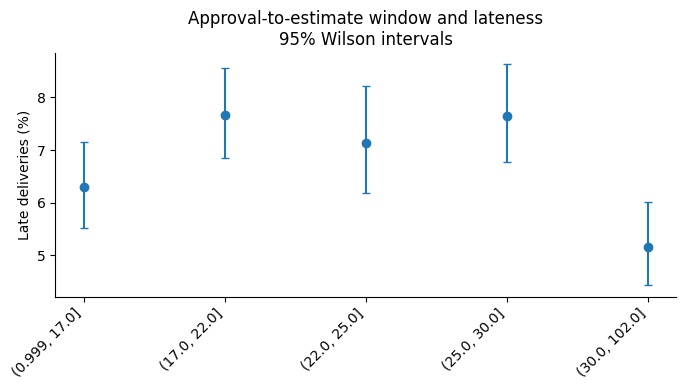

**Required question 2 — promise window.** Quantile bands avoid assuming linearity and keep reasonable group sizes; cut points are exploratory. The supported band (17.0, 22.0] had the highest observed rate (7.7%, n=3,656); (30.0, 102.0] had 5.2% (n=2,983). Confidence intervals describe sampling uncertainty, while state, season, basket and seller mix may explain differences. Longer promises also change the deadline against which lateness is measured, so this is not evidence that lengthening promises improves logistics. Review promise calibration by route and period before changing customer commitments.

In [20]:
labelled["promise_band"] = bands(labelled["promise_window_days"])
promise = rates(labelled, "promise_band")
save(promise, "03_analysis/promise_rates.csv", "One data-driven promise-window band; labelled-order denominator")
rate_chart(promise, "promise_band", "Approval-to-estimate window and lateness", "promise_window")
supported = promise.loc[promise["screening_support"]]
if not supported.empty:
    high, low = supported.loc[supported.rate.idxmax()], supported.loc[supported.rate.idxmin()]
    note(f"**Required question 2 — promise window.** Quantile bands avoid assuming linearity and keep reasonable group sizes; cut points are exploratory. The supported band {high.promise_band} had the highest observed rate ({high.rate:.1%}, n={high.n:,}); {low.promise_band} had {low.rate:.1%} (n={low.n:,}). Confidence intervals describe sampling uncertainty, while state, season, basket and seller mix may explain differences. Longer promises also change the deadline against which lateness is measured, so this is not evidence that lengthening promises improves logistics. Review promise calibration by route and period before changing customer commitments.")

### 3.3 Which customer states merit investigation

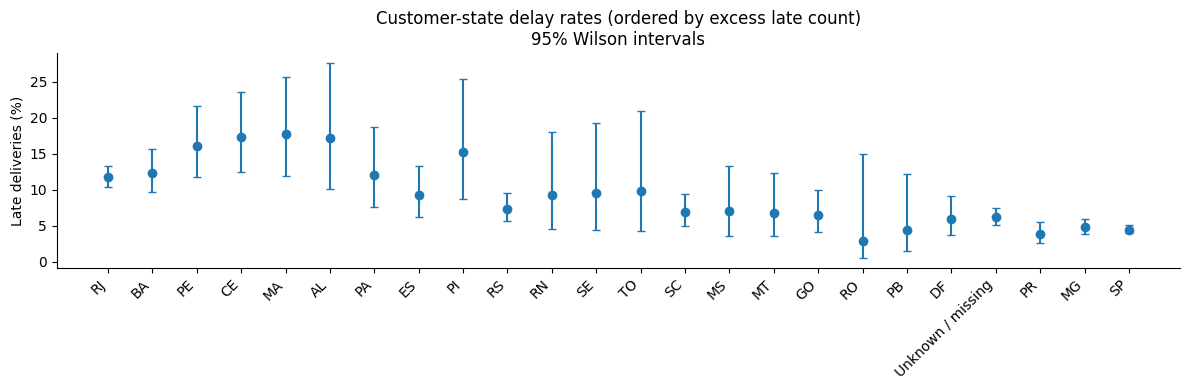

**Required question 3 — states and investigation priority.** RJ: 11.7%, 1,835 labelled orders, 90.2 excess late orders; BA: 12.4%, 477 labelled orders, 26.6 excess late orders; PE: 16.1%, 217 labelled orders, 20.2 excess late orders. Excess counts combine volume and rate; they are not causal or statistically significant excesses. All states and unknown geography remain in the export; groups below 30 labelled orders do not receive priority claims. State routes, seller concentration, season and promise windows can confound comparisons. Investigate routes with both material volume and high rates, then verify operational records before allocating capacity.

In [21]:
state_rates = rates(labelled, "customer_state")
state_rates["observed_excess_late_orders"] = state_rates["late"] - state_rates["n"] * row.rate
state_rates = state_rates.sort_values(["observed_excess_late_orders", "n"], ascending=False)
save(state_rates, "03_analysis/state_priority.csv", "One buyer-state group; rates, severity, and descriptive excess late count versus overall rate")
rate_chart(state_rates, "customer_state", "Customer-state delay rates (ordered by excess late count)", "state_rates")
priorities = state_rates.loc[state_rates.screening_support & state_rates.customer_state.ne("Unknown / missing")].head(3)
evidence = "; ".join(f"{r.customer_state}: {r.rate:.1%}, {int(r.n):,} labelled orders, {r.observed_excess_late_orders:.1f} excess late orders" for r in priorities.itertuples())
note(f"**Required question 3 — states and investigation priority.** {evidence or 'No state has enough support for screening'}. Excess counts combine volume and rate; they are not causal or statistically significant excesses. All states and unknown geography remain in the export; groups below {MIN_GROUP} labelled orders do not receive priority claims. State routes, seller concentration, season and promise windows can confound comparisons. Investigate routes with both material volume and high rates, then verify operational records before allocating capacity.")

### 3.4 Compare frequency with delay severity

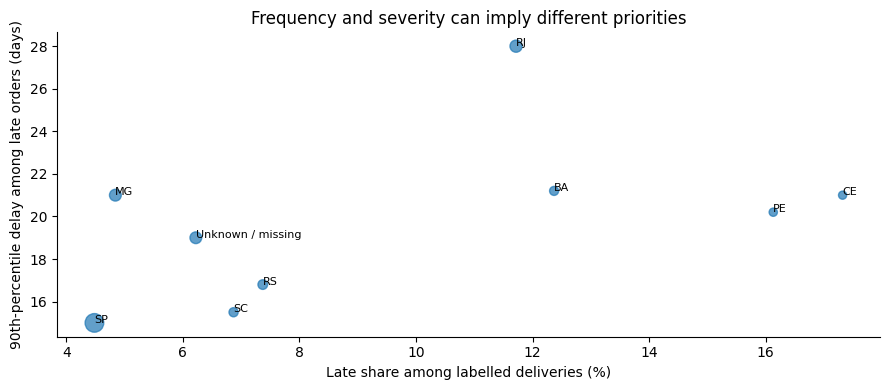

**Further question — do frequency and severity tell the same story?** RJ has the largest supported late-delay 90th percentile (28.0 days; 215 late deliveries), with a late share of 11.7%. The scatter compares two different denominators: frequency uses all usable deliveries, severity only late deliveries. Tail quantiles are less stable than averages; there is no interval for the tail estimate here. Investigate exceptionally delayed routes as well as frequent delays, without treating sparse tail observations as a state-wide service standard.

In [22]:
severity = state_rates.loc[state_rates.screening_support & state_rates.late.ge(MIN_GROUP)].copy()
if not severity.empty:
    plt.figure()
    plt.scatter(severity["rate"]*100, severity["late_p90_days"], s=30+150*severity["n"]/severity["n"].max(), alpha=0.7)
    for r in severity.itertuples():
        plt.annotate(r.customer_state, (r.rate*100, r.late_p90_days), fontsize=8)
    plt.xlabel("Late share among labelled deliveries (%)")
    plt.ylabel("90th-percentile delay among late orders (days)")
    plt.title("Frequency and severity can imply different priorities")
    figure("state_frequency_severity", severity, "One state with sufficient labelled and late orders; bubble area reflects labelled volume")
    worst = severity.loc[severity.late_p90_days.idxmax()]
    note(f"**Further question — do frequency and severity tell the same story?** {worst.customer_state} has the largest supported late-delay 90th percentile ({worst.late_p90_days:.1f} days; {int(worst.late)} late deliveries), with a late share of {worst.rate:.1%}. The scatter compares two different denominators: frequency uses all usable deliveries, severity only late deliveries. Tail quantiles are less stable than averages; there is no interval for the tail estimate here. Investigate exceptionally delayed routes as well as frequent delays, without treating sparse tail observations as a state-wide service standard.")

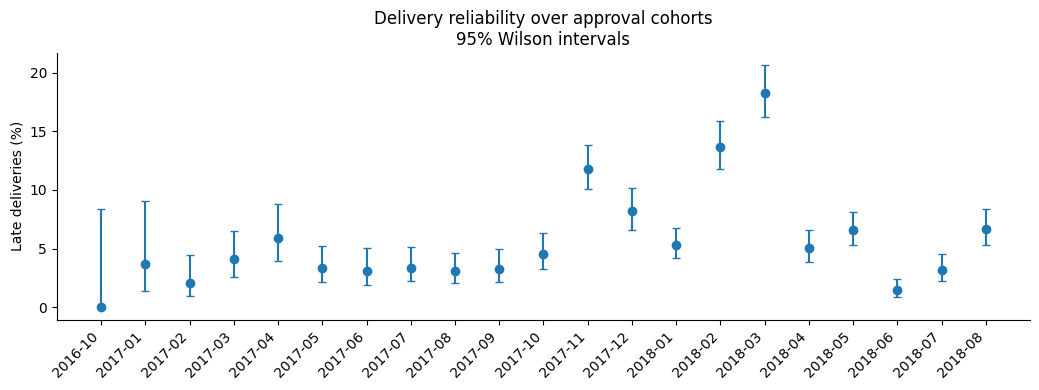

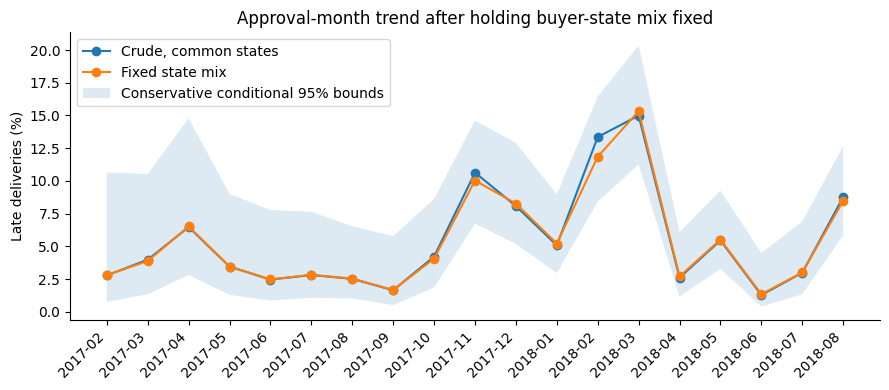

**Further question — reliability over time and order mix.** Common support allows comparison across 19 months and 2 states, restricted to months with enough observations of both pooled most-represented states (SP, RJ). Within that common cohort, fixed-state-mix rates range from 1.3% to 15.3%; the largest absolute mix adjustment is 1.5%. Shaded conservative bounds combine Bonferroni-adjusted Wilson cell intervals and still assume binomial cell uncertainty; shared-seller dependence can widen uncertainty. This descriptive adjustment controls only buyer-state composition and discards unsupported strata; it does not establish a time effect or account for seller/promise changes. Investigate cohort shifts alongside dispatch capacity and promises. Recent orders may have incomplete follow-up; the extract provides no observation cutoff, so trends are conditional on reliable completed outcomes.

In [23]:
# Calendar cohorts and a common-state comparison help examine changing order mix.
labelled["approval_month"] = labelled["order_approved_at"].dt.to_period("M").astype(str)
monthly = rates(labelled, "approval_month").sort_values("approval_month")
save(monthly, "03_analysis/monthly_rates.csv", "One approval-month cohort; usable completed deliveries only")
rate_chart(monthly, "approval_month", "Delivery reliability over approval cohorts", "monthly_rates")
month_state = labelled.loc[labelled.customer_state.notna()].groupby(["approval_month", "customer_state"]).agg(n=("late", "size"), late=("late", "sum"))
month_state["rate"] = month_state["late"] / month_state["n"]
save(month_state.reset_index(), "03_analysis/month_state_cells.csv", "One observed month/state cell; input to mix standardisation")
supported_months = monthly.loc[monthly.screening_support, "approval_month"]
anchor_states = labelled["customer_state"].value_counts().head(2).index
if len(anchor_states) == 2:
    # Select comparable months using counts only, before examining their late rates.
    anchor_counts = month_state["n"].unstack("customer_state").reindex(columns=anchor_states).fillna(0)
    anchor_support = anchor_counts.ge(MIN_GROUP).all(axis=1)
    supported_months = supported_months[supported_months.map(anchor_support).fillna(False)]
cell_counts = month_state["n"].unstack("customer_state").reindex(supported_months).fillna(0)
common_states = cell_counts.columns[cell_counts.ge(MIN_GROUP).all(axis=0)] if len(cell_counts) else []
if len(common_states) > 1 and len(supported_months) > 1:
    cells_common = month_state.loc[pd.IndexSlice[supported_months, common_states], :].reset_index()
    weights = cells_common.groupby("customer_state")["n"].sum()
    weights = weights / weights.sum()
    cells_common["common_weight"] = cells_common["customer_state"].map(weights)
    cells_common["weighted_rate"] = cells_common["rate"] * cells_common["common_weight"]
    # Bonferroni-adjusted cell intervals give conservative bounds on the weighted rate.
    low, high = wilson(cells_common["late"], cells_common["n"], confidence=1-(1-CONFIDENCE)/len(weights))
    cells_common["weighted_low"] = low*cells_common["common_weight"]
    cells_common["weighted_high"] = high*cells_common["common_weight"]
    standardised = cells_common.groupby("approval_month").agg(standardised_rate=("weighted_rate", "sum"), common_cohort_n=("n", "sum"))
    standardised = standardised.join(cells_common.groupby("approval_month")[["weighted_low", "weighted_high"]].sum())
    standardised = standardised.join(cells_common.groupby("approval_month").apply(lambda d: d["late"].sum()/d["n"].sum(), include_groups=False).rename("common_crude_rate"))
    save(standardised.reset_index(), "03_analysis/monthly_standardised.csv", "One supported month; crude and standardised rates restricted to common supported states")
    save(weights.rename("weight").reset_index(), "03_analysis/standardisation_weights.csv", "One common state; pooled common-cohort weight")
    plt.figure()
    plt.plot(standardised.index, standardised["common_crude_rate"]*100, marker="o", label="Crude, common states")
    plt.plot(standardised.index, standardised["standardised_rate"]*100, marker="o", label="Fixed state mix")
    plt.fill_between(standardised.index, standardised["weighted_low"]*100, standardised["weighted_high"]*100, alpha=0.15, label="Conservative conditional 95% bounds")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Late deliveries (%)")
    plt.title("Approval-month trend after holding buyer-state mix fixed")
    plt.legend()
    figure("monthly_mix_adjustment", standardised.reset_index(), "One supported month; both series restricted to the same common-state cohort")
    note(f"**Further question — reliability over time and order mix.** Common support allows comparison across {len(standardised)} months and {len(weights)} states, restricted to months with enough observations of both pooled most-represented states ({', '.join(anchor_states)}). Within that common cohort, fixed-state-mix rates range from {standardised.standardised_rate.min():.1%} to {standardised.standardised_rate.max():.1%}; the largest absolute mix adjustment is {(standardised.standardised_rate-standardised.common_crude_rate).abs().max():.1%}. Shaded conservative bounds combine Bonferroni-adjusted Wilson cell intervals and still assume binomial cell uncertainty; shared-seller dependence can widen uncertainty. This descriptive adjustment controls only buyer-state composition and discards unsupported strata; it does not establish a time effect or account for seller/promise changes. Investigate cohort shifts alongside dispatch capacity and promises. Recent orders may have incomplete follow-up; the extract provides no observation cutoff, so trends are conditional on reliable completed outcomes.")
else:
    note("**Further question — reliability over time.** Monthly cohorts are exported, but common state/month support is insufficient for a stable mix-adjusted comparison. No adjustment is manufactured. Completion selection, seller mix and changing promises are alternatives to an operational time effect; the extract gives no observation cutoff. Gather a complete follow-up window before acting on the newest cohort.")

### 3.6 Basket value, item count and freight

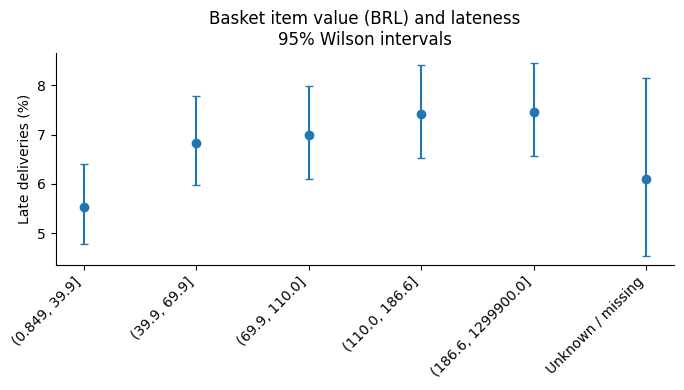

**Further question — basket item value (brl).** Observed supported rates span 5.5% (n=3,104, (0.849, 39.9]; 95% interval 4.8%–6.4%) to 7.5% (n=2,991, (186.6, 1299900.0]; interval 6.6%–8.5%). Quantile bands expose possible nonlinearity; missing totals are shown separately. Groups near the minimum-support threshold can still have wide intervals. These unadjusted groups differ in category, route, period and promises, and unverified extreme values may distort the bands. Investigate the composition of high-rate baskets before changing handling procedures, freight pricing or customer prioritisation; the chart shows association only.

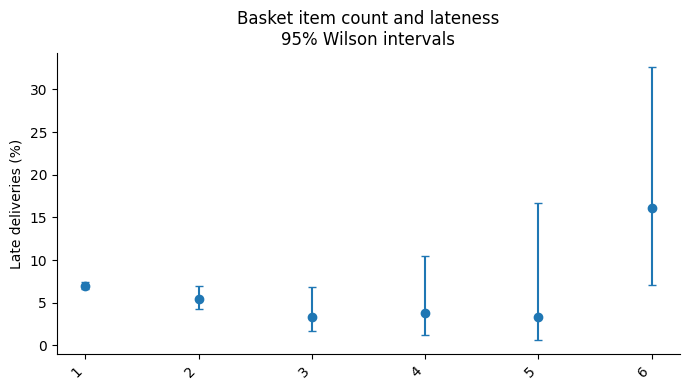

**Further question — basket item count.** Observed supported rates span 3.3% (n=30, 5; 95% interval 0.6%–16.7%) to 16.1% (n=31, 6; interval 7.1%–32.6%). Exact item counts expose possible nonlinearity; missing totals are shown separately. Groups near the minimum-support threshold can still have wide intervals. These unadjusted groups differ in category, route, period and promises, and unverified extreme values may distort the bands. Investigate the composition of high-rate baskets before changing handling procedures, freight pricing or customer prioritisation; the chart shows association only.

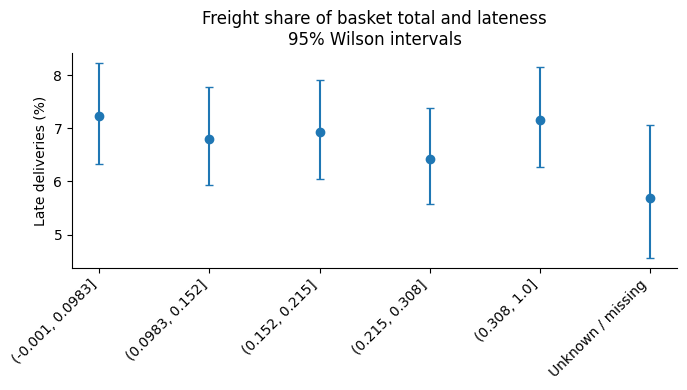

**Further question — freight share of basket total.** Observed supported rates span 6.4% (n=2,866, (0.215, 0.308]; 95% interval 5.6%–7.4%) to 7.2% (n=2,866, (-0.001, 0.0983]; interval 6.3%–8.2%). Quantile bands expose possible nonlinearity; missing totals are shown separately. Groups near the minimum-support threshold can still have wide intervals. These unadjusted groups differ in category, route, period and promises, and unverified extreme values may distort the bands. Investigate the composition of high-rate baskets before changing handling procedures, freight pricing or customer prioritisation; the chart shows association only.

In [24]:
for column, title in [("basket_value_brl", "Basket item value (BRL)"), ("item_count", "Basket item count"), ("freight_share", "Freight share of basket total")]:
    group = column + "_band"
    method = "Quantile bands"
    if column == "item_count":
        values = labelled[column].astype("Int64").astype("string")
        categories = [str(int(value)) for value in sorted(labelled[column].dropna().unique())]
        labelled[group] = pd.Categorical(values, categories=categories, ordered=True)
        method = "Exact item counts"
    else:
        labelled[group] = bands(labelled[column])
    table = rates(labelled, group)
    save(table, f"03_analysis/{column}_rates.csv", f"One {column} quantile band; unknown values have their own denominator")
    supported = table.loc[table.screening_support & table[group].ne("Unknown / missing")]
    if len(supported) > 1:
        rate_chart(table, group, title + " and lateness", column)
        high, low = supported.loc[supported.rate.idxmax()], supported.loc[supported.rate.idxmin()]
        note(f"**Further question — {title.lower()}.** Observed supported rates span {low.rate:.1%} (n={int(low.n):,}, {low[group]}; 95% interval {low.low:.1%}–{low.high:.1%}) to {high.rate:.1%} (n={int(high.n):,}, {high[group]}; interval {high.low:.1%}–{high.high:.1%}). {method} expose possible nonlinearity; missing totals are shown separately. Groups near the minimum-support threshold can still have wide intervals. These unadjusted groups differ in category, route, period and promises, and unverified extreme values may distort the bands. Investigate the composition of high-rate baskets before changing handling procedures, freight pricing or customer prioritisation; the chart shows association only.")
    else:
        note(f"**Candidate question — {title.lower()}.** Fewer than two supported observed groups are available, so a comparative chart is omitted. The exported table preserves the counts without claiming a pattern.")

### 3.7 Seller–buyer geography

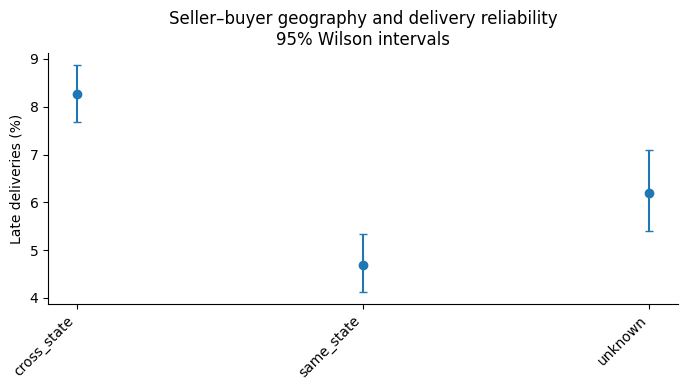

**Further question — seller–buyer geography.** cross_state: 8.3% (n=7,991, 95% interval 7.7%–8.9%); same_state: 4.7% (n=4,560, 95% interval 4.1%–5.3%). The chart compares baskets whose sellers all share the buyer's state, all differ, or are mixed; any unknown seller/buyer state makes the order's group unknown. State differences are a coarse route proxy, not kilometres or transport time. Seller mix and promises may explain the pattern, and missing geography can be selective. Operations can review route-level hand-offs, but should obtain actual distance and carrier data before claiming a distance effect.

,geography,n,late,late_median_days,late_p90_days,rate,low,high,screening_support
0,cross_state,7991,660,8.0,25.0,0.082593,7.675628e-02,0.088831,True
1,mixed_states,28,0,NaN,NaN,0.000000,1.387779e-17,0.120643,False
2,same_state,4560,214,4.0,13.7,0.046930,4.116356e-02,0.053459,True
3,unknown,3069,190,7.0,21.0,0.061909,5.391874e-02,0.070995,True


In [25]:
geo = rates(labelled, "geography")
save(geo, "03_analysis/geography_rates.csv", "One same/cross/mixed/unknown seller-buyer state group; labelled-order denominator")
rate_chart(geo, "geography", "Seller–buyer geography and delivery reliability", "geography")
geo_supported = geo.loc[geo.screening_support & geo.geography.ne("unknown")]
geo_evidence = "; ".join(f"{r.geography}: {r.rate:.1%} (n={int(r.n):,}, 95% interval {r.low:.1%}–{r.high:.1%})" for r in geo_supported.itertuples())
note(f"**Further question — seller–buyer geography.** {geo_evidence or 'No known-geography group meets the support threshold'}. The chart compares baskets whose sellers all share the buyer's state, all differ, or are mixed; any unknown seller/buyer state makes the order's group unknown. State differences are a coarse route proxy, not kilometres or transport time. Seller mix and promises may explain the pattern, and missing geography can be selective. Operations can review route-level hand-offs, but should obtain actual distance and carrier data before claiming a distance effect.")
display(geo)

### 3.8 Product-category screening

In [26]:
category = rates(labelled, "dominant_category").sort_values("n", ascending=False)
translation = clean["category_translation"].set_index("product_category_name")["product_category_name_english"]
category["category_english"] = category["dominant_category"].map(translation)
category["category_display"] = category["category_english"].fillna(category["dominant_category"])
save(category, "03_analysis/category_screening.csv", "One dominant product-category group; ties resolved by item count then name")
display(category.head(10))
category_supported = category.head(10).loc[lambda d: d.screening_support & d.dominant_category.ne("Unknown / missing")]
category_evidence = "; ".join(f"{r.category_display}: {r.rate:.1%} (n={int(r.n):,})" for r in category_supported.nlargest(3, "rate").itertuples())
note(f"**Further question — product characteristics.** Among the ten most represented category groups, the largest supported observed rates are {category_evidence or 'unavailable'}. The table screens represented baskets rather than ranking noisy small categories. Its denominator is one labelled order per dominant item-count category; multi-category baskets are simplified and untranslated categories keep their original names. Many simultaneous comparisons and route/seller confounding limit interpretation; intervals are in the export. Use these groups as candidates for packaging/handling investigation, then validate on another period; no category is declared a causal risk factor.")

,dominant_category,n,late,late_median_days,late_p90_days,rate,low,high,screening_support,category_english,category_display
14,cama_mesa_banho,1428,101,8.0,29.0,0.070728,0.058551,0.085209,True,bed_bath_table,bed_bath_table
12,beleza_saude,1267,93,6.0,17.0,0.073402,0.060295,0.089088,True,health_beauty,health_beauty
0,Unknown / missing,1185,87,5.0,22.0,0.073418,0.059906,0.089686,True,<NA>,Unknown / missing
33,esporte_lazer,1100,71,7.0,29.0,0.064545,0.051486,0.080636,True,sports_leisure,sports_leisure
45,informatica_acessorios,947,69,6.0,21.0,0.072862,0.057977,0.091197,True,computers_accessories,computers_accessories
55,moveis_decoracao,924,61,6.0,27.0,0.066017,0.051736,0.083892,True,furniture_decor,furniture_decor
73,utilidades_domesticas,844,47,6.0,16.2,0.055687,0.042134,0.073267,True,housewares,housewares
67,relogios_presentes,805,51,8.0,21.0,0.063354,0.048513,0.082343,True,watches_gifts,watches_gifts
70,telefonia,617,49,6.0,18.6,0.079417,0.060591,0.103446,True,telephony,telephony
9,automotivo,585,59,6.0,27.2,0.100855,0.078997,0.127920,True,auto,auto


**Further question — product characteristics.** Among the ten most represented category groups, the largest supported observed rates are auto: 10.1% (n=585); telephony: 7.9% (n=617); health_beauty: 7.3% (n=1,267). The table screens represented baskets rather than ranking noisy small categories. Its denominator is one labelled order per dominant item-count category; multi-category baskets are simplified and untranslated categories keep their original names. Many simultaneous comparisons and route/seller confounding limit interpretation; intervals are in the export. Use these groups as candidates for packaging/handling investigation, then validate on another period; no category is declared a causal risk factor.

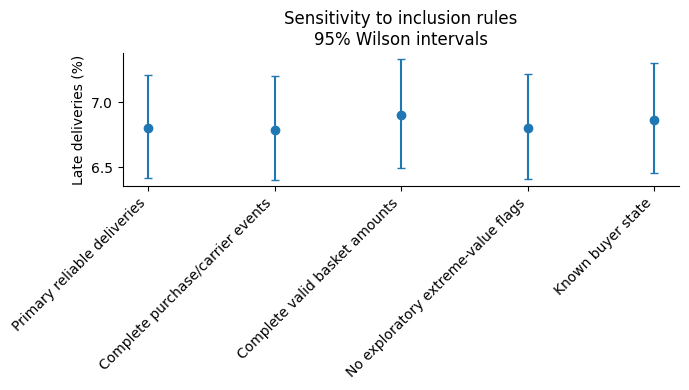

In [27]:
# Cleaning sensitivity changes inclusion criteria, never repairs specific records.
complete_events = labelled[["order_purchase_timestamp", "order_delivered_carrier_date"]].notna().all(axis=1)
complete_basket = labelled["basket_value_brl"].notna() & labelled["freight_brl"].notna()
scenarios = {
    "Primary reliable deliveries": pd.Series(True, index=labelled.index),
    "Complete purchase/carrier events": complete_events,
    "Complete valid basket amounts": complete_basket,
    "No exploratory extreme-value flags": ~labelled["extreme_positive_value"],
    "Known buyer state": labelled["customer_state"].notna(),
}
sensitivity, state_sensitivity = [], []
for name, mask in scenarios.items():
    subset = labelled.loc[mask]
    if subset.empty:
        sensitivity.append({"scenario": name, "n": 0, "late": 0, "rate": np.nan})
        continue
    summary = rates(subset.assign(scenario=name), "scenario")
    summary["late_median_days"] = subset.loc[subset.late.eq(1), "delay_days"].median()
    sensitivity.extend(summary.to_dict("records"))
    states = rates(subset, "customer_state")
    states["scenario"] = name
    state_sensitivity.append(states)
sensitivity = pd.DataFrame(sensitivity)
save(sensitivity, "03_analysis/sensitivity.csv", "One rule-based inclusion scenario; same primary labels, different cohorts")
state_sensitivity = pd.concat(state_sensitivity, ignore_index=True)
state_sensitivity["scenario_rate"] = state_sensitivity["scenario"].map(sensitivity.set_index("scenario")["rate"])
state_sensitivity["excess_late_orders"] = state_sensitivity["late"] - state_sensitivity["n"]*state_sensitivity["scenario_rate"]
priority_sensitivity = state_sensitivity.loc[state_sensitivity.screening_support & state_sensitivity.customer_state.ne("Unknown / missing")].copy()
priority_sensitivity["priority_rank"] = priority_sensitivity.groupby("scenario")["excess_late_orders"].rank(method="min", ascending=False)
save(priority_sensitivity, "03_analysis/state_priority_sensitivity.csv", "One supported state/scenario; rank by descriptive excess late count")
save(state_sensitivity, "03_analysis/state_sensitivity.csv", "One state/scenario; checks robustness of geographic conclusions")
rate_chart(sensitivity.assign(screening_support=sensitivity["n"].ge(MIN_GROUP)), "scenario", "Sensitivity to inclusion rules", "cleaning_sensitivity")

### 3.10 Missingness and robustness of priorities

In [28]:
coverage_by_state = orders.assign(customer_state=orders.customer_state.fillna("Unknown / missing")).groupby("customer_state").agg(
    all_orders=("order_id", "size"), labelled_orders=("label_usable", "sum"), approval_eligible=("approval_eligible", "sum"))
coverage_by_state["label_coverage"] = coverage_by_state["labelled_orders"] / coverage_by_state["all_orders"]
save(coverage_by_state.reset_index(), "03_analysis/state_label_coverage.csv", "One buyer state; label selection relative to all original orders")
customer_repetition = labelled["customer_unique_id"].dropna().value_counts()
repeated_orders = int(customer_repetition.loc[customer_repetition.gt(1)].sum())
priority_evidence = "; ".join(f"{name}: {', '.join(d.sort_values('priority_rank').head(3).customer_state)}" for name, d in priority_sensitivity.groupby("scenario"))
note(f"**State priority robustness.** The top three supported excess-count priorities in each cohort are {priority_evidence or 'unavailable'}. Agreement strengthens screening stability within this extract; disagreement calls for investigating which excluded records change the ranking. It does not remove route, promise or seller confounding.")
note(f"**Robustness and confidence.** Across the tested cohorts, late rates range from {sensitivity.rate.min():.1%} to {sensitivity.rate.max():.1%}; denominators change and the cohorts overlap, so differences are descriptive rather than independent hypothesis tests. The state/scenario export shows whether priority conclusions survive inclusion changes, while state coverage reveals selective missing outcomes. {repeated_orders:,} labelled orders belong to observed repeat customers; unknown customer links and shared sellers can add dependence, making Wilson intervals optimistic. Extreme positive values were retained in the primary results and removed only in an explicitly named sensitivity cohort. Investigate missingness and unresolved units before using these associations for policy or extrapolating to the original Olist population.")
display(sensitivity, coverage_by_state)
end_step(meter, memory_of([orders, labelled, state_sensitivity]))

**State priority robustness.** The top three supported excess-count priorities in each cohort are Complete purchase/carrier events: RJ, BA, PE; Complete valid basket amounts: RJ, BA, PE; Known buyer state: RJ, BA, PE; No exploratory extreme-value flags: RJ, BA, PE; Primary reliable deliveries: RJ, BA, PE. Agreement strengthens screening stability within this extract; disagreement calls for investigating which excluded records change the ranking. It does not remove route, promise or seller confounding.

**Robustness and confidence.** Across the tested cohorts, late rates range from 6.8% to 6.9%; denominators change and the cohorts overlap, so differences are descriptive rather than independent hypothesis tests. The state/scenario export shows whether priority conclusions survive inclusion changes, while state coverage reveals selective missing outcomes. 134 labelled orders belong to observed repeat customers; unknown customer links and shared sellers can add dependence, making Wilson intervals optimistic. Extreme positive values were retained in the primary results and removed only in an explicitly named sensitivity cohort. Investigate missingness and unresolved units before using these associations for policy or extrapolating to the original Olist population.

,scenario,n,late,late_median_days,late_p90_days,rate,low,high,screening_support
0,Primary reliable deliveries,15648,1064,7.0,22.0,0.067996,0.064157,0.072047,True
1,Complete purchase/carrier events,15335,1041,7.0,22.0,0.067884,0.064010,0.071974,True
2,Complete valid basket amounts,14329,989,7.0,22.0,0.069021,0.064985,0.073288,True
3,No exploratory extreme-value flags,15061,1024,7.0,22.0,0.067990,0.064079,0.072122,True
4,Known buyer state,14025,963,7.0,22.0,0.068663,0.064595,0.072967,True


,all_orders,labelled_orders,approval_eligible,label_coverage
customer_state,,,,
AC,17,14,17,0.823529
AL,87,70,86,0.804598
AM,29,22,28,0.758621
AP,9,8,8,0.888889
BA,613,477,586,0.77814
CE,234,179,228,0.764957
DF,379,303,371,0.799472
ES,343,260,330,0.758017
GO,365,279,354,0.764384


## 4. Feature Engineering (20%)

Keep one row per approval-eligible order, including unlabelled outcomes. Export IDs, nullable labels,
and features separately. A chronological split holds out the latest approval dates; all medians,
category vocabularies and constant-column decisions are learned on **training records only**.
There is no fitted prediction model in this assignment.

The predictor allowlist uses basket counts/value/freight, catalogue measurements/completeness,
buyer location, seller–buyer geography, promised calendar-day window, and purchase-to-approval
wait. Log transforms reduce the influence of large positive amounts without guessing unit repairs.
Hour, weekday and month use cyclical sine/cosine pairs. State/category/geography use training-only
one-hot categories; missing and unseen values have explicit buckets. High-cardinality order,
customer, product and seller IDs are not predictors. Low-dimensional catalogue measurements
are preferred to redundant individual product IDs.

Final status, actual shipment/delivery events, payments, reviews, labels, exclusions derived from
outcomes, and `shipping_limit_date` are absent from the predictor allowlist. Missing-value indicators
are kept even when no training record is missing, so future missingness has explicit behaviour.
Unverifiable extreme positive values remain unresolved; feature scaling does not make them correct.

In [29]:
meter = begin_step("4_features", memory_of([orders]) * 4)
FEATURE_MEANINGS = {
    "item_count": "Purchased item rows", "seller_count": "Distinct supplied seller IDs", "product_count": "Distinct supplied product IDs",
    "category_count": "Distinct known item categories", "basket_value_brl": "Complete item-price sum in BRL",
    "freight_brl": "Complete item-freight sum in BRL", "weight_g": "Complete summed item product weights in grams",
    "volume_cm3": "Complete summed length × height × width in cubic centimetres",
    "freight_share": "Freight divided by item value plus freight; missing for zero/incomplete total",
    "mean_photos": "Mean known product photo count across items; partial coverage allowed",
    "catalogue_missing_fraction": "Item share lacking category or weight",
    "seller_geography_known_fraction": "Item share with both buyer and seller states known",
    "cross_state_fraction": "Cross-state item share among items with known geography",
    "product_orphan_count": "Item references missing from the product lookup", "seller_orphan_count": "Item references missing from seller lookup",
    "price_missing_count": "Item price values unavailable after domain validation",
    "freight_missing_count": "Item freight values unavailable after domain validation",
    "no_item_records": "No supplied item rows; distinguish missing basket from true zero",
    "customer_orphan": "Order customer reference absent from lookup",
    "promise_window_days": "Estimated calendar date minus approval calendar date",
    "approval_wait_hours": "Recorded approval minus purchase in hours; unknown if purchase unavailable",
}
LOG_COLUMNS = ["basket_value_brl", "freight_brl", "weight_g", "volume_cm3", "approval_wait_hours"]
CATEGORICAL = ["customer_state", "dominant_category", "geography"]

### 4.1 Reusable approval-time feature transformations

In [30]:
def feature_inputs(frame):
    result = frame[list(FEATURE_MEANINGS) + CATEGORICAL].copy()
    for column in LOG_COLUMNS:
        result["log1p_" + column] = np.log1p(result.pop(column))
    approved = frame["order_approved_at"]
    for name, value, period in [("hour", approved.dt.hour + approved.dt.minute/60, 24),
                                ("weekday", approved.dt.dayofweek, 7), ("month", approved.dt.month-1, 12)]:
        result[name + "_sin"] = np.sin(2*np.pi*value/period)
        result[name + "_cos"] = np.cos(2*np.pi*value/period)
    return result

def encode_category(series):
    # Prefix actual values so they cannot collide with reserved missing/unseen buckets.
    return series.astype("string").map(lambda value: "__MISSING__" if pd.isna(value) else "value:" + str(value))

def fit_features(training):
    numeric = [c for c in training if c not in CATEGORICAL]
    numbers = training[numeric].astype(float).replace([np.inf, -np.inf], np.nan)
    medians = numbers.median().fillna(0)  # All-missing training field: explicit zero plus missing indicator.
    filled = numbers.fillna(medians)
    kept = [c for c in numeric if filled[c].nunique() > 1]
    vocabulary = {c: sorted(set(encode_category(training[c])) | {"__MISSING__", "__UNSEEN__"}) for c in CATEGORICAL}
    return {"numeric": numeric, "kept_numeric": kept, "medians": medians.to_dict(), "categories": vocabulary,
            "dropped_constant_numeric": [c for c in numeric if c not in kept]}

def transform_features(frame, fitted):
    numbers = frame[fitted["numeric"]].astype(float).replace([np.inf, -np.inf], np.nan)
    pieces = [numbers.fillna(fitted["medians"])[fitted["kept_numeric"]]]
    for column in fitted["numeric"]:
        pieces.append(numbers[column].isna().astype(int).rename(column + "__missing"))
    for column, vocabulary in fitted["categories"].items():
        values = encode_category(frame[column])
        values = values.where(values.isin(vocabulary), "__UNSEEN__")
        for value in vocabulary:
            pieces.append(values.eq(value).astype(int).rename(column + "=" + value))
    return pd.concat(pieces, axis=1).astype(float)

### 4.2 Temporal split and training-only preprocessing

In [31]:
retained = orders.loc[orders.approval_eligible].sort_values(["order_approved_at", "order_id"]).reset_index(drop=True)
days = sorted(retained["order_approved_at"].dt.normalize().unique())
if len(days) < 2:
    raise ValueError("At least two approval dates are needed for a chronological train/holdout split.")
boundary = min(len(days)-1, max(1, math.floor(len(days)*(1-HOLDOUT_FRACTION))))
cutoff = pd.Timestamp(days[boundary])
split = np.where(retained["order_approved_at"].dt.normalize().lt(cutoff), "train", "holdout")
inputs = feature_inputs(retained)
fitted = fit_features(inputs.loc[split == "train"])
X = transform_features(inputs, fitted)
assert np.isfinite(X.to_numpy()).all() and all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes)
assert len(X) == len(retained) and retained["order_id"].is_unique
assert set(inputs) == set(fitted["numeric"]) | set(CATEGORICAL)

### 4.3 Export aligned features, IDs and labels

In [32]:
ids = retained[["order_id"]].copy()
ids.insert(0, "row_id", np.arange(len(ids)))
labels = pd.DataFrame({"row_id": ids.row_id, "delivered_after_estimate": retained.delivered_after_estimate})
split_table = pd.DataFrame({"row_id": ids.row_id, "split": split, "label_available": labels.delivered_after_estimate.notna()})
save(X, "04_features/features.csv", "One approval-eligible order per row; numeric predictors only; row order matches order_ids.csv")
save(ids, "04_features/order_ids.csv", "Feature row number and order identifier, kept separate from predictors")
save(labels, "04_features/labels.csv", "Feature row number and nullable reliable delivery label; blank is unknown")
save(split_table, "04_features/split.csv", "Chronological training/holdout membership and label availability")
save(inputs, "04_features/feature_inputs.csv", "Unencoded approval-time feature inputs in matching row order")
(OUT / "04_features/transformer.json").write_text(json.dumps(fitted, indent=2, sort_keys=True), encoding="utf-8")

5496

### 4.4 Explain every predictor and record learned preprocessing

In [33]:
dictionary = []
for column in X:
    base = column.removesuffix("__missing")
    if "=" in column:
        source, value = column.split("=", 1)
        meaning = f"One-hot {source}: {value}; vocabulary learned on training only"
    elif base.startswith("log1p_"):
        meaning = "Natural log(1 + x) of " + FEATURE_MEANINGS[base.removeprefix("log1p_")]
    elif base.endswith(("_sin", "_cos")):
        meaning = "Cyclical " + base + " of approval local clock"
    else:
        meaning = FEATURE_MEANINGS.get(base, base)
    if column.endswith("__missing"):
        meaning = "1 if unavailable before training-median imputation: " + meaning
    dictionary.append({"feature": column, "meaning": meaning, "available_at": "approval", "source": base})
save(pd.DataFrame(dictionary), "04_features/feature_dictionary.csv", "One numerical predictor and its interpretation")
save(pd.DataFrame({"field": fitted["numeric"], "training_median": [fitted["medians"][c] for c in fitted["numeric"]],
                   "constant_value_column_dropped": [c in fitted["dropped_constant_numeric"] for c in fitted["numeric"]]}),
     "04_features/training_preprocessing.csv", "One numeric input; training-only imputation and constant-column decision")
display(split_table.groupby(["split", "label_available"]).size().rename("orders").reset_index())
display(Markdown(f"Retained {len(retained):,} approval-eligible orders with {X.shape[1]} numerical predictors. The holdout starts on {cutoff.date()}. Feature rows are aligned through `order_ids.csv`; supervised training must filter to available labels **after** applying the saved split. Preprocessing is fitted on training approval records without looking at labels. This split checks future-time behaviour within the extract, not external validity."))
end_step(meter, memory_of([inputs, X, retained]))

,split,label_available,orders
0,holdout,False,1039
1,holdout,True,4108
2,train,False,2630
3,train,True,11540


Retained 19,317 approval-eligible orders with 162 numerical predictors. The holdout starts on 2018-04-29. Feature rows are aligned through `order_ids.csv`; supervised training must filter to available labels **after** applying the saved split. Preprocessing is fitted on training approval records without looking at labels. This split checks future-time behaviour within the extract, not external validity.

## 5. Reproducibility and Documentation (10%)

The following tests cover business-rule edge cases and broken relationships, rather than just
checking that the provided extract ran. Resource measurements include the kernel and child RSS
sampled every 50 ms; allocator peaks between samples can be missed. Existing dataframes from
earlier steps remain resident. Incremental RSS can be smaller than dataframe sizes because memory
is reused. The loading import briefly holds the SQL text; its temporary SQLite file is subsequently
renamed into the output directory. Later steps use in-memory intermediates rather than temporary
disk joins. CSV storage estimates extrapolate the first 500 rows and can miss long text tails.

Stage estimates are transparent planning heuristics based on input bytes or dataframe footprint,
not measurements disguised as estimates. The exported comparison reports estimates, runtime,
sampled peak and incremental memory, intermediate dataframe storage, and output disk growth.
On reruns, disk growth differs from total retained storage. PDF/report writing remains a separate
submission task; chart data, findings, checks and provenance below support it. Temporary import disk
is estimated from SQL size and observed from the completed temporary SQLite file before its rename;
that observation excludes transient journal peaks. No disk-based intermediates are used in later steps.
Dataframe footprints are logical sizes and can count shared objects more than once; RSS measures
process memory. Package-import startup and final checksum/manifest writes sit outside stage timings.

In [34]:
meter = begin_step("5_validation_documentation", memory_of([X]) * 2)
test_results = []
def check(name, assertion):
    assertion()
    test_results.append({"test": name, "passed": True})

def assert_true(condition):
    assert bool(condition)

def example_orders(**overrides):
    values = {"order_status": "delivered", "order_purchase_timestamp": "2024-01-01 10:00:00",
              "order_approved_at": "2024-01-01 12:00:00", "order_delivered_carrier_date": "2024-01-02 10:00:00",
              "order_delivered_customer_date": "2024-01-05 23:59:59", "order_estimated_delivery_date": "2024-01-05 00:00:00"}
    values.update(overrides)
    frame = pd.DataFrame([values])
    frame["order_status"] = normalise(frame["order_status"])
    for column in [c for c in values if c != "order_status"]:
        parsed = parse_dates(frame[column])
        frame[column + "_invalid"] = frame[column].notna() & parsed.isna()
        frame[column] = parsed
    return label_orders(frame)[0]

### 5.1 Representative edge cases

In [35]:
check("Same-calendar-day delivery is on time", lambda: assert_true(example_orders().delivered_after_estimate.iloc[0] == 0))
check("Next calendar day is late", lambda: assert_true(example_orders(order_delivered_customer_date="2024-01-06 00:00:01").delivered_after_estimate.iloc[0] == 1))
check("Cancelled with delivery timestamp stays unlabelled", lambda: assert_true(example_orders(order_status="canceled").delivered_after_estimate.isna().all()))
check("Unknown status stays unlabelled", lambda: assert_true(example_orders(order_status="new_status").delivered_after_estimate.isna().all()))
check("Malformed February date is flagged, not repaired", lambda: assert_true(example_orders(order_delivered_customer_date="2024-02-30 12:00:00").invalid_recorded_date.all()))
check("Observed chronology contradiction invalidates label", lambda: assert_true(example_orders(order_delivered_carrier_date="2024-01-06 10:00:00").delivered_after_estimate.isna().all()))
check("Approval before purchase is not prediction eligible", lambda: assert_true(~example_orders(order_approved_at="2023-12-31 12:00:00").approval_eligible.iloc[0]))
check("Missing approval leaves unknown label", lambda: assert_true(example_orders(order_approved_at=None).delivered_after_estimate.isna().all()))
check("Missing optional carrier still allows consistent label", lambda: assert_true(example_orders(order_delivered_carrier_date=None).label_usable.iloc[0]))
check("Malformed optional carrier cannot masquerade as absent", lambda: assert_true(~example_orders(order_delivered_carrier_date="bad").label_usable.iloc[0]))
check("Estimate on approval day is valid", lambda: assert_true(example_orders(order_estimated_delivery_date="2024-01-01 00:00:00").approval_eligible.iloc[0]))
check("Estimate before approval day is rejected", lambda: assert_true(~example_orders(order_estimated_delivery_date="2023-12-31 00:00:00").approval_eligible.iloc[0]))
check("Declared slash and ISO-T date formats agree", lambda: assert_true(parse_dates(pd.Series(["05/01/2024 10:00:00", "2024-01-05T10:00:00"])).nunique() == 1))
check("Zero money is valid; negative and infinite are missing", lambda: assert_true(valid_numbers(pd.Series([0, -1, np.inf, None])).isna().tolist() == [False, True, True, True]))
check("Text-typed numeric columns validate, not silently skip", lambda: assert_true(valid_numbers(pd.Series(["12.5", "bad", "-2"])).isna().tolist() == [False, True, True]))
check("Raw numeric aggregates preserve missing, not invented zero", lambda: assert_true(finite_numeric(pd.Series(["bad", np.inf, None, "2.5"])).notna().tolist() == [False, False, False, True]))
check("Zero installments valid; negative/fractional invalid", lambda: assert_true(valid_numbers(pd.Series([0, -1, 1.5]), integer=True).isna().tolist() == [False, True, True]))
check("Review range is respected", lambda: assert_true(valid_numbers(pd.Series([1, 5, 0, 8]), minimum=1, maximum=5, integer=True).isna().tolist() == [False, False, True, True]))
check("Partial sums are not complete totals", lambda: assert_true(pd.isna(sum_complete(pd.Series([10, np.nan])))))
check("All-missing sums stay missing", lambda: assert_true(pd.isna(sum_complete(pd.Series([np.nan, np.nan])))))

### 5.2 Relationships and preprocessing edge cases

In [36]:
def test_join():
    base = pd.DataFrame({"order_id": ["a", "b"], "customer_id": ["known", "orphan"]})
    customer = pd.DataFrame({"customer_id": ["known"], "customer_state": ["SP"]})
    item = pd.DataFrame({"order_id": ["a", "a"], "amount": [10., 20.]}).groupby("order_id").agg(item_count=("amount", "size"), amount=("amount", "sum"))
    payment = pd.DataFrame({"order_id": ["a", "a", "a"], "payment": [1., 2., 3.]}).groupby("order_id").sum()
    review = pd.DataFrame({"order_id": ["a", "a"], "review": [4., 5.]}).groupby("order_id").mean()
    result = assemble(base, customer, item, payment, review)
    assert len(result) == 2 and result.amount.sum() == 30 and pd.isna(result.loc[1, "customer_state"])
check("Multi-child joins preserve amounts and orphan orders", test_join)

def test_encoding():
    training = pd.DataFrame({"amount": [10., 20., np.nan], "all_missing": [np.nan]*3,
                             "customer_state": ["SP"]*3, "dominant_category": ["a", "a", None], "geography": ["same_state"]*3})
    fitted_test = fit_features(training)
    future = training.iloc[:1].copy()
    future["amount"], future["all_missing"] = np.nan, 99.
    future["customer_state"], future["dominant_category"] = "NEW", None
    transformed = transform_features(future, fitted_test)
    assert transformed.amount.iloc[0] == 15 and fitted_test["medians"]["amount"] == 15
    assert transformed["customer_state=__UNSEEN__"].iloc[0] == 1
    assert transformed["dominant_category=__MISSING__"].iloc[0] == 1
    assert transformed["amount__missing"].iloc[0] == 1
    assert list(transformed) == list(transform_features(training, fitted_test))
    assert np.isfinite(transformed.to_numpy()).all()
check("Training-only median, unseen categories and all-missing fields", test_encoding)

def test_optional_catalogue():
    missing_catalogue = retained.loc[retained.catalogue_missing_fraction.gt(0)].head(2)
    if missing_catalogue.empty:
        missing_catalogue = retained.head(1).copy()
        missing_catalogue["weight_g"], missing_catalogue["dominant_category"] = np.nan, pd.NA
    assert len(transform_features(feature_inputs(missing_catalogue), fitted)) == len(missing_catalogue)
check("Optional catalogue gaps do not discard feature rows", test_optional_catalogue)
def test_no_outcome_leakage():
    changed = retained.head(3).copy()
    before = feature_inputs(changed)
    for column in ["order_status", "order_delivered_carrier_date", "order_delivered_customer_date", "payment_brl", "mean_review_score", "delivered_after_estimate"]:
        changed[column] = pd.NA
    pd.testing.assert_frame_equal(before, feature_inputs(changed))
check("Changing post-approval outcomes cannot change predictors", test_no_outcome_leakage)
check("Constant/missing quantile input has explicit behaviour", lambda: assert_true(bands(pd.Series([1., 1., np.nan])).notna().all()))
check("Original SQL hash unchanged", lambda: assert_true(file_hash(RAW_SQL) == INPUT_HASH))
check("Exported IDs, labels and predictors align", lambda: assert_true(len(pd.read_csv(OUT/'04_features/features.csv')) == len(ids) == len(labels)))
save(pd.DataFrame(test_results), "05_reproducibility/tests.csv", "One representative business-rule or pipeline test")
display(pd.DataFrame(test_results))

,test,passed
0,Same-calendar-day delivery is on time,True
1,Next calendar day is late,True
2,Cancelled with delivery timestamp stays unlabe...,True
3,Unknown status stays unlabelled,True
4,"Malformed February date is flagged, not repaired",True
5,Observed chronology contradiction invalidates ...,True
6,Approval before purchase is not prediction eli...,True
7,Missing approval leaves unknown label,True
8,Missing optional carrier still allows consiste...,True
9,Malformed optional carrier cannot masquerade a...,True


In [37]:
configuration = {"input_name": RAW_SQL.name, "input_sha256": INPUT_HASH, "minimum_group_orders": MIN_GROUP,
                 "holdout_fraction_of_approval_dates": HOLDOUT_FRACTION, "confidence_level": CONFIDENCE,
                 "exploratory_extreme_quantile": EXTREME_QUANTILE, "date_formats": DATE_FORMATS,
                 "holdout_start": str(cutoff.date()), "python": platform.python_version(),
                 "platform": platform.platform(), "logical_cpus": psutil.cpu_count(), "system_ram_bytes": psutil.virtual_memory().total,
                 "packages": {name: metadata.version(name) for name in ["pandas", "numpy", "matplotlib", "scipy", "pycountry", "psutil", "nbformat", "nbclient", "ipykernel"]}}
(OUT / "05_reproducibility/environment.json").write_text(json.dumps(configuration, indent=2, sort_keys=True), encoding="utf-8")
(OUT / "05_reproducibility/executed_queries.sql").write_text(";\n\n".join(sql_log) + ";\n", encoding="utf-8")
(OUT / "05_reproducibility/findings.md").write_text("# Computed business findings\n\n" + "\n\n".join(notes), encoding="utf-8")
end_step(meter, memory_of([X]))
save(pd.DataFrame(resources), "05_reproducibility/resources.csv", "One assessed step; elapsed runtime, estimated/measured memory and export storage")

inventory_files = []
for path in sorted(OUT.rglob("*")):
    if path.is_file() and path.name not in ["file_checksums.csv", "README.md", "manifest.csv"]:
        inventory_files.append({"file": str(path.relative_to(OUT)), "bytes": path.stat().st_size, "sha256": file_hash(path)})
save(pd.DataFrame(inventory_files), "05_reproducibility/file_checksums.csv", "One generated artifact with size and SHA-256; resource timings are expected to vary")
manifest = pd.DataFrame(artifacts).drop_duplicates("file", keep="last").sort_values("file")
manifest.to_csv(OUT / "05_reproducibility/manifest.csv", index=False)
mapping = "\n".join(f"| `{a.file}` | {a.rows} | {a.meaning} |" for a in manifest.itertuples())
readme = f"""# Generated assignment outputs

Reproduce from the repository with `python run_notebook.py` after installing
`requirements-notebook.txt`. To change input/output paths, set RAW_SQL and OUTPUT_DIR.
MIN_GROUP controls analysis screening; HOLDOUT_FRACTION controls the chronological split.
The pipeline overwrites its own named generated artifacts only; it never writes to raw.sql.
Do not place user-maintained files in this generated directory. Use a new output directory
when changing input or configuration; optional artifacts from an earlier run may otherwise remain.

Input SHA-256: `{INPUT_HASH}`. All files derive from this input and rules in the notebook.
Open CSVs with pandas.read_csv; parse dates explicitly and use nullable Int64 for labels.
Blank delivery labels are unknown, not on time. Boolean CSV columns represent quality flags.
For modelling, load features.csv, order_ids.csv, labels.csv and split.csv together;
assert equal lengths, use row_id to align, and select labelled training rows only.
Load transformer.json to reuse training medians/categories with transform_features in the notebook.
The raw.sqlite file is a faithful imported working copy; open it read-only for comparison.
PNG charts have corresponding chart_data CSVs. SQL schema names/types and actual executed
queries are saved; raw.sql itself is the import source. Findings are conditional associations.

Steps: 01 imports raw SQL and assembles raw orders; 02 validates/cleans those tables and
assembles audited orders; 03 analyses reliable outcomes; 04 creates approval-time features
for all eligible orders; 05 tests the pipeline and records provenance and resources.
No fitted model, final PDF report or causal claims are produced.

## File map

| File | Rows | Row meaning and loading notes |
| --- | ---: | --- |
{mapping}

Resource CSV units are bytes and seconds. RSS includes retained earlier objects and children,
sampled every 50 ms. Output disk growth is a delta, not total storage. CSV estimates use a
500-row sample. Peak temporary import disk is approximately one SQLite database; SQL text
is held in memory during import. Later joins use in-memory temporary frames. Intermediate
dataframe bytes count explicitly listed frames, not every Python object or allocator buffer.
Training-only category discovery and medians prevent holdout leakage; temporal validation
does not ensure labels would have matured at a historical deployment cutoff.
"""
(OUT / "README.md").write_text(readme, encoding="utf-8")
display(pd.DataFrame(resources).round(3))
comparison = "; ".join(f"{r['step']}: {r['estimated_incremental_bytes']/1024**2:.1f} MiB planned vs {r['measured_incremental_rss_bytes']/1024**2:.1f} MiB sampled additional RSS, {r['runtime_seconds']:.2f} s" for r in resources)
display(Markdown("**Resource comparison (current run).** " + comparison + ". Planning heuristics are approximate; samples can miss short-lived peaks, and memory reuse reduces later increments. CSV estimates and actual storage are recorded separately in bytes. Re-measure at larger scale rather than multiplying these timings blindly."))
display(Markdown(f"**Completed:** {len(test_results)} representative tests passed; original SQL unchanged. All five steps produced documented artifacts in `{OUT.name}`. Read `05_reproducibility/findings.md` for computed conclusions and limitations, and the generated `README.md` for every CSV's row meaning. Compare estimates with measured RSS/storage before choosing a larger-scale implementation."))

,step,baseline_rss_bytes,sampled_peak_rss_bytes,estimated_incremental_bytes,estimated_temporary_disk_bytes,observed_temporary_database_bytes,runtime_seconds,measured_incremental_rss_bytes,intermediate_dataframe_bytes,estimated_csv_bytes,actual_csv_bytes,output_disk_growth_bytes
0,1_loading,164679680,259919872,73057152,18264288,24363008,3.833,95240192,67285846,5459474,5440299,-4
1,2_cleaning,235282432,303251456,117918945,0,0,9.729,67969024,65079062,49502959,54003329,0
2,3_analysis,303292416,336154624,38243760,0,0,3.024,32862208,35219022,72443,72443,0
3,4_features,336154624,413278208,76487520,0,0,3.109,77123584,50742914,14478849,14530015,0
4,5_validation_documentation,413278208,419844096,50069928,0,0,0.355,6565888,25034964,1389,1389,0


**Resource comparison (current run).** 1_loading: 69.7 MiB planned vs 90.8 MiB sampled additional RSS, 3.83 s; 2_cleaning: 112.5 MiB planned vs 64.8 MiB sampled additional RSS, 9.73 s; 3_analysis: 36.5 MiB planned vs 31.3 MiB sampled additional RSS, 3.02 s; 4_features: 72.9 MiB planned vs 73.6 MiB sampled additional RSS, 3.11 s; 5_validation_documentation: 47.8 MiB planned vs 6.3 MiB sampled additional RSS, 0.35 s. Planning heuristics are approximate; samples can miss short-lived peaks, and memory reuse reduces later increments. CSV estimates and actual storage are recorded separately in bytes. Re-measure at larger scale rather than multiplying these timings blindly.

**Completed:** 27 representative tests passed; original SQL unchanged. All five steps produced documented artifacts in `assignment_outputs`. Read `05_reproducibility/findings.md` for computed conclusions and limitations, and the generated `README.md` for every CSV's row meaning. Compare estimates with measured RSS/storage before choosing a larger-scale implementation.